# 🎓 LUẬN VĂN: TabNet + XAI cho IEC 104 IDS

## Cấu trúc notebook:
| Phần | Nội dung | Dùng cho |
|------|----------|----------|
| 1 | Load dữ liệu & model TabNet | Chuẩn bị |
| 2 | XAI Tầng 1: TabNet Intrinsic Attention | Mục 4.x |
| 3 | XAI Tầng 2: SHAP — Global | Mục 4.x |
| 4 | XAI Tầng 2: SHAP — Per-class | Mục 4.x |
| 5 | XAI Tầng 2: SHAP — Local (từng mẫu) | Mục 4.x |
| 6 | So sánh Attention vs SHAP | Mục 4.x |
| 7 | Tổng kết & lưu kết quả | Chương 4 |

> **Yêu cầu**: Đã có `tabnet_iec104_model.zip`, `X_train/val/test.csv`, `y_train/val/test.csv`, `label_encoder.pkl`

---
## ⚙️ BƯỚC 0: Cài đặt thư viện

In [1]:
import sys
!{sys.executable} -m pip install lime

You should consider upgrading via the 'c:\Users\Admin\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [2]:
!pip install shap pytorch-tabnet matplotlib seaborn

import shap
print(f'✓ SHAP version: {shap.__version__}')

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.1.1 -> 26.1.2
[notice] To update, run: C:\Python313\python.exe -m pip install --upgrade pip


✓ SHAP version: 0.49.1


---
## 📦 PHẦN 1: Load dữ liệu và model TabNet

In [3]:
import pandas as pd
import numpy as np
import time
import json
import pickle
import warnings
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import shap
from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score
from sklearn.preprocessing import label_binarize

warnings.filterwarnings('ignore')
np.random.seed(42)

# ================================================
# ĐỔI ĐƯỜNG DẪN NÀY THEO MÁY CỦA BẠN
data_dir = "../data/processed/"
# ================================================

# Load dữ liệu
X_train = pd.read_csv(data_dir + "X_train.csv")
X_val   = pd.read_csv(data_dir + "X_val.csv")
X_test  = pd.read_csv(data_dir + "X_test.csv")
y_train = pd.read_csv(data_dir + "y_train.csv").values.ravel()
y_val   = pd.read_csv(data_dir + "y_val.csv").values.ravel()
y_test  = pd.read_csv(data_dir + "y_test.csv").values.ravel()

with open(data_dir + "label_encoder.pkl", "rb") as f:
    label_encoder = pickle.load(f)
label_names  = label_encoder.classes_
feature_names = list(X_train.columns)
n_classes    = len(label_names)

print(f'✓ Train:      {X_train.shape}')
print(f'✓ Validation: {X_val.shape}')
print(f'✓ Test:       {X_test.shape}')
print(f'✓ Features:   {len(feature_names)}')
print(f'\nPhân bố nhãn trong tập Test:')
print(f'{"Lớp":<30} {"Số mẫu":>8} {"Tỷ lệ":>8}')
print('-' * 50)
for i, name in enumerate(label_names):
    cnt = np.sum(y_test == i)
    pct = cnt / len(y_test) * 100
    print(f'{name:<30} {cnt:>8} {pct:>7.2f}%')

✓ Train:      (224107, 78)
✓ Validation: (47868, 78)
✓ Test:       (47996, 78)
✓ Features:   78

Phân bố nhãn trong tập Test:
Lớp                              Số mẫu    Tỷ lệ
--------------------------------------------------
attackfree                           38    0.08%
dosattack                         45694   95.20%
floodattack                          16    0.03%
fuzzyattack                         141    0.29%
iec104starvationattack              304    0.63%
mitmattack                            4    0.01%
ntpddosattack                       342    0.71%
portscanattack                     1457    3.04%


In [4]:
# Load model TabNet đã train
model = TabNetClassifier()
model.load_model(data_dir + "tabnet_iec104_model.zip.zip")

# Dự đoán trên tập test
y_pred       = model.predict(X_test.values)
y_pred_proba = model.predict_proba(X_test.values)

# Tính các metrics
acc = accuracy_score(y_test, y_pred)
p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')
y_test_bin  = label_binarize(y_test, classes=range(n_classes))
auc = roc_auc_score(y_test_bin, y_pred_proba, multi_class='ovr', average='macro')

print(f'✓ Model loaded thành công!')
print(f'\n  Accuracy:      {acc*100:.2f}%')
print(f'  Macro F1:      {f1:.4f}')
print(f'  Macro AUC:     {auc:.4f}')

✓ Model loaded thành công!

  Accuracy:      99.62%
  Macro F1:      0.8908
  Macro AUC:     0.9995


In [5]:

try:
    with open(data_dir + 'timing_training.json', 'r', encoding='utf-8') as f:
        timing = json.load(f)
    print("Đã tải timing huấn luyện từ TABNET.ipynb:", timing)
except FileNotFoundError:
    timing = {}
    print("⚠ Chưa có file timing_training.json")

Đã tải timing huấn luyện từ TABNET.ipynb: {'tabnet_training_sec': 3226.844484500005, 'tabnet_epochs_actual': 24, 'tabnet_sec_per_epoch': 134.45185352083354}


---
## 🔍 PHẦN 2: XAI Tầng 1 — TabNet Intrinsic Attention

TabNet tích hợp **Sequential Attention** bên trong kiến trúc.  
Tại mỗi bước quyết định (`n_steps=5`), mô hình **tự chọn tập features** cần chú ý.  
Đây là **intrinsic XAI** — không cần công cụ bên ngoài.

3 góc nhìn:
- **2.1** Global: Feature nào quan trọng nhất trên toàn dataset
- **2.2** Per-step: Mỗi bước quyết định chú ý feature nào
- **2.3** Per-class: Feature nào quan trọng khi phát hiện từng lớp tấn công

Thời gian tính Attention cho 47996 mẫu: 10.709s (0.223 ms/mẫu)
Tính xong! Shape explain_matrix: (47996, 78)
 Tổng importance (phải = 1.0): 52.7064
✓ Đã lưu: att_global.png


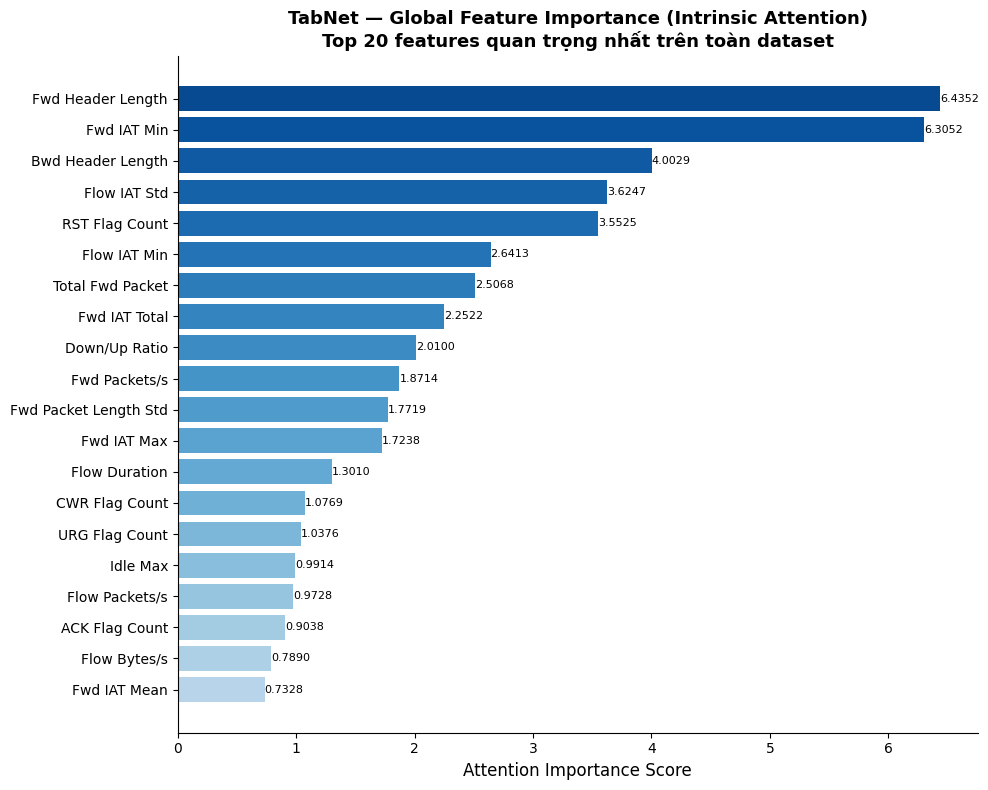


Top 10 features (Attention): ['Fwd Header Length', 'Fwd IAT Min', 'Bwd Header Length', 'Flow IAT Std', 'RST Flag Count', 'Flow IAT Min', 'Total Fwd Packet', 'Fwd IAT Total', 'Down/Up Ratio', 'Fwd Packets/s']


In [6]:
# -----------------------------------------------
# 2.1 Global Feature Importance từ Attention
#
# Sau khi load model từ file, feature_importances_
# chưa được tính sẵn → cần dùng explain() để tính lại
# explain() trả về aggregated attention mask
# shape: (n_samples, n_features)
# → mean theo axis=0 = global feature importance
# -----------------------------------------------

t0 = time.perf_counter()
explain_matrix, masks = model.explain(X_test.values)
timing['attention_explain_sec'] = time.perf_counter() - t0
timing['attention_explain_n_samples'] = len(X_test)
timing['attention_sec_per_sample'] = timing['attention_explain_sec'] / len(X_test)

print(f"Thời gian tính Attention cho {len(X_test)} mẫu: "
      f"{timing['attention_explain_sec']:.3f}s "
      f"({timing['attention_sec_per_sample']*1000:.3f} ms/mẫu)")
# explain_matrix: (n_samples, n_features) — aggregated attention

# Bước 2: Global importance = trung bình attention toàn bộ test set
feat_imp   = explain_matrix.mean(axis=0)  # shape: (n_features,)
sorted_idx = np.argsort(feat_imp)[::-1]   # Sắp xếp giảm dần
top_n = 20

print(f'Tính xong! Shape explain_matrix: {explain_matrix.shape}')
print(f' Tổng importance (phải = 1.0): {feat_imp.sum():.4f}')

top_scores = feat_imp[sorted_idx[:top_n]][::-1]
top_labels = [feature_names[i] for i in sorted_idx[:top_n]][::-1]
colors_bar = plt.cm.Blues(np.linspace(0.3, 0.9, top_n))

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(range(top_n), top_scores, color=colors_bar)
ax.set_yticks(range(top_n))
ax.set_yticklabels(top_labels, fontsize=10)
ax.set_xlabel('Attention Importance Score', fontsize=12)
ax.set_title('TabNet — Global Feature Importance (Intrinsic Attention)\n'
             'Top 20 features quan trọng nhất trên toàn dataset',
             fontsize=13, fontweight='bold')
for bar, val in zip(bars, top_scores):
    ax.text(val + 0.0005, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(data_dir + 'att_global.png', dpi=300, bbox_inches='tight')
print('✓ Đã lưu: att_global.png')
plt.show()

# Lưu lại để dùng ở các phần sau
top10_attention = [feature_names[i] for i in sorted_idx[:10]]
print(f'\nTop 10 features (Attention): {top10_attention}')

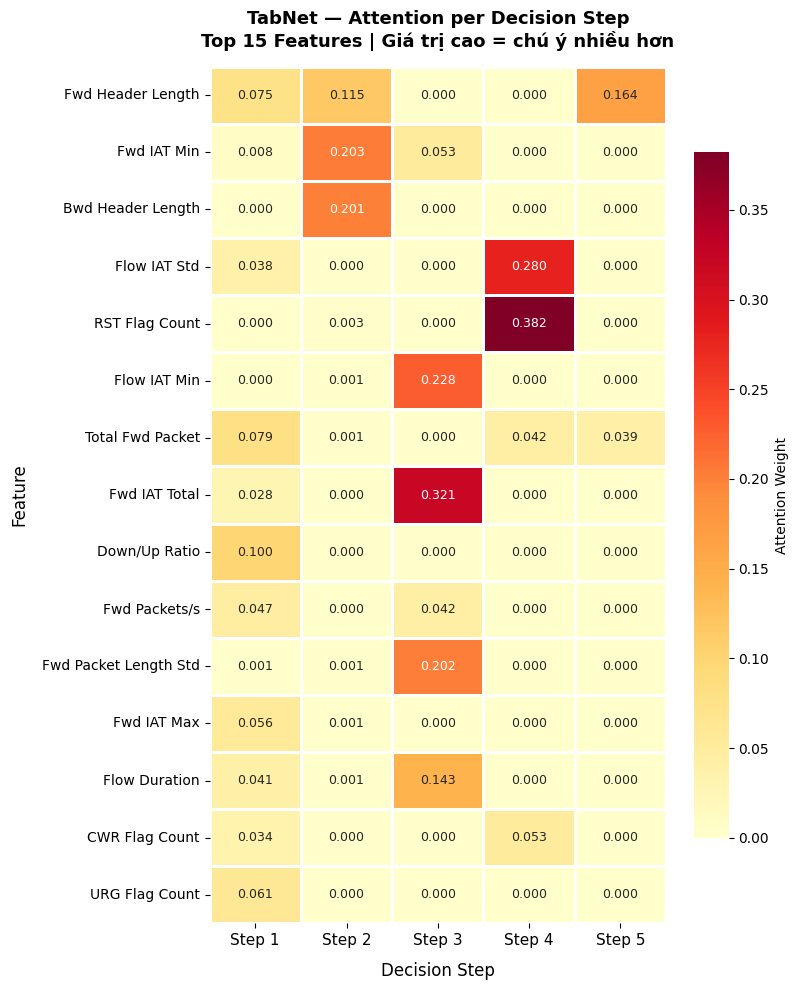

In [7]:
# -----------------------------------------------
# 2.2 Attention per Decision Step — Heatmap 
# -----------------------------------------------
n_steps      = len(masks)
top_k_step   = 15
top_feat_idx = sorted_idx[:top_k_step]

step_att   = np.zeros((n_steps, top_k_step))
masks_list = list(masks) if isinstance(masks, dict) else masks

for s in range(n_steps):
    mask_s     = masks_list[s] if isinstance(masks, list) else masks[s]
    step_att[s] = mask_s[:, top_feat_idx].mean(axis=0)

feat_labels_short = [feature_names[i][:22] for i in top_feat_idx]

# ── Tăng figsize, tăng font, xoay label rõ hơn ──
fig, ax = plt.subplots(figsize=(8, 10))  # dọc thay vì ngang

sns.heatmap(
    step_att.T,              # .T để transpose — features thành hàng, steps thành cột
    annot=True,
    fmt='.3f',
    annot_kws={'size': 9},
    xticklabels=[f'Step {s+1}' for s in range(n_steps)],  # steps trên trục X
    yticklabels=feat_labels_short,                          # features trên trục Y
    cmap='YlOrRd',
    linewidths=1.0,
    linecolor='white',
    cbar_kws={'shrink': 0.8, 'label': 'Attention Weight'},
    ax=ax
)

ax.set_xlabel('Decision Step', fontsize=12, labelpad=10)
ax.set_ylabel('Feature', fontsize=12, labelpad=10)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=11)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=10)

ax.set_title(
    'TabNet — Attention per Decision Step\n'
    'Top 15 Features | Giá trị cao = chú ý nhiều hơn',
    fontsize=13, fontweight='bold', pad=14
)

plt.tight_layout()
plt.savefig(data_dir + 'att_per_step.png', dpi=300, bbox_inches='tight')
plt.show()

✓ Đã lưu: att_per_class.png


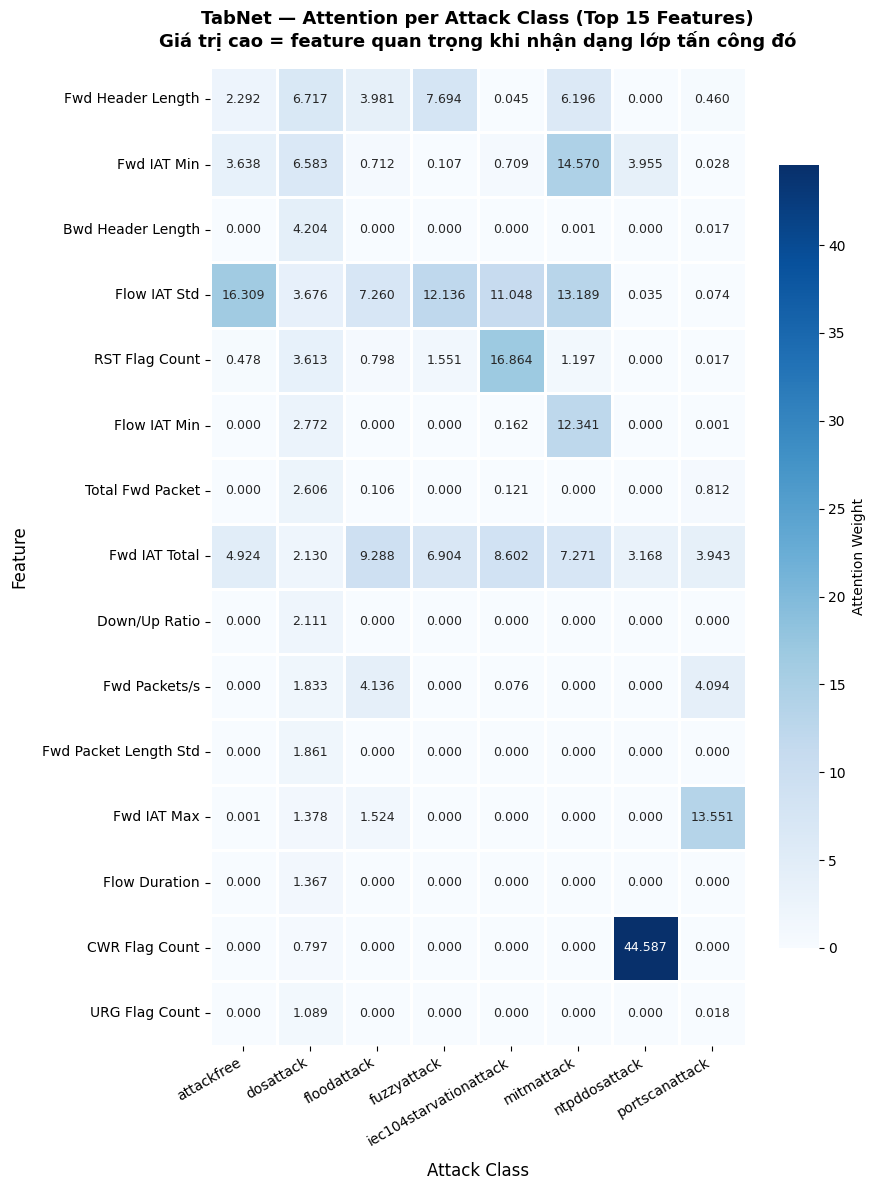


 Feature quan trọng nhất theo từng lớp:
  attackfree                → Flow IAT Std                   (16.3085)
  dosattack                 → Fwd Header Length              (6.7168)
  floodattack               → Fwd IAT Total                  (9.2884)
  fuzzyattack               → Flow IAT Std                   (12.1359)
  iec104starvationattack    → RST Flag Count                 (16.8641)
  mitmattack                → Fwd IAT Min                    (14.5704)
  ntpddosattack             → CWR Flag Count                 (44.5872)
  portscanattack            → Fwd IAT Max                    (13.5508)


In [8]:
# -----------------------------------------------
# 2.3 Attention per Attack Class — Heatmap
#
# Dùng lại explain_matrix đã tính ở cell 2.1
# KHÔNG gọi model.explain() lại — tốn RAM và thời gian
# -----------------------------------------------

# explain_matrix đã có từ cell 2.1 (toàn bộ X_test)
# Nếu cell 2.1 dùng X_test.values[:300] thì cần
# lấy y_test tương ứng
n_explain = explain_matrix.shape[0]  # Số mẫu đã explain
y_test_sub = y_test[:n_explain]      # Lấy nhãn tương ứng

top_k_cls        = 15
class_att_matrix = np.zeros((n_classes, top_k_cls))

for cls_idx in range(n_classes):
    mask_cls = (y_test_sub == cls_idx)
    if mask_cls.sum() == 0:
        print(f'  Lớp "{label_names[cls_idx]}" không có mẫu trong {n_explain} mẫu đầu')
        continue
    class_att_matrix[cls_idx] = (
        explain_matrix[mask_cls][:, sorted_idx[:top_k_cls]].mean(axis=0)
    )

feat_labels = [feature_names[i][:22] for i in sorted_idx[:top_k_cls]]

# ── Layout cải thiện ──
fig, ax = plt.subplots(figsize=(9, 12))  # dọc, vừa trang A4

sns.heatmap(
    class_att_matrix.T,              # .T — features thành hàng, lớp thành cột
    annot=True,
    fmt='.3f',
    annot_kws={'size': 9},
    xticklabels=label_names,         # lớp tấn công trên trục X
    yticklabels=feat_labels,         # features trên trục Y
    cmap='Blues',
    linewidths=1.0,
    linecolor='white',
    cbar_kws={'shrink': 0.8, 'label': 'Attention Weight'},
    ax=ax
)

ax.set_title(
    'TabNet — Attention per Attack Class (Top 15 Features)\n'
    'Giá trị cao = feature quan trọng khi nhận dạng lớp tấn công đó',
    fontsize=13, fontweight='bold', pad=14
)
ax.set_xlabel('Attack Class', fontsize=12, labelpad=10)
ax.set_ylabel('Feature', fontsize=12, labelpad=10)

ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right', fontsize=10)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=10)

plt.tight_layout()
plt.savefig(data_dir + 'att_per_class.png', dpi=300, bbox_inches='tight')
print('✓ Đã lưu: att_per_class.png')
plt.show()
# Tóm tắt: lớp nào chú ý feature nào nhiều nhất
print('\n Feature quan trọng nhất theo từng lớp:')
for cls_idx, cls_name in enumerate(label_names):
    top_feat_for_cls = np.argmax(class_att_matrix[cls_idx])
    top_val          = class_att_matrix[cls_idx][top_feat_for_cls]
    top_feat_name    = feature_names[sorted_idx[top_feat_for_cls]]
    print(f'  {cls_name:<25} → {top_feat_name:<30} ({top_val:.4f})')

---
## 🧠 PHẦN 3: XAI Tầng 2 — SHAP Global Explanation

**SHAP (SHapley Additive exPlanations)** dựa trên lý thuyết trò chơi Shapley.  
Với mỗi dự đoán, SHAP trả lời: *"Feature X đóng góp bao nhiêu vào kết quả này?"*

**Tại sao dùng SHAP thêm vào sau Attention?**
- Attention giải thích *quá trình* (mô hình nhìn vào đâu)
- SHAP giải thích *kết quả* (feature đẩy output lên/xuống bao nhiêu)
- Hai tầng bổ trợ nhau → độ tin cậy cao hơn

In [9]:
# -----------------------------------------------
# Setup SHAP KernelExplainer
#
# KernelExplainer: model-agnostic, dùng được với TabNet
# Background = kmeans(50): 50 điểm đại diện từ train
#   → Nhanh hơn dùng toàn bộ train set
#   → Đủ chính xác cho luận văn
# -----------------------------------------------
print('Đang chuẩn bị SHAP Explainer (kmeans background)...')

def predict_fn(x):
    """Wrapper: numpy array → xác suất từng lớp"""
    return model.predict_proba(x)

background  = shap.kmeans(X_train.values, 50)
explainer   = shap.KernelExplainer(predict_fn, background)
print('✓ SHAP Explainer sẵn sàng!')

Đang chuẩn bị SHAP Explainer (kmeans background)...
✓ SHAP Explainer sẵn sàng!


In [10]:
# -----------------------------------------------
# Tính SHAP values — Stratified sampling
#
# Lấy mẫu đều từ mỗi lớp (stratified) để đảm bảo
# tất cả loại tấn công đều được đại diện
#

n_shap_samples = 100

shap_indices = []
n_per_class  = max(1, n_shap_samples // n_classes)
for cls_idx in range(n_classes):
    idx_cls = np.where(y_test == cls_idx)[0]
    n_take  = min(len(idx_cls), n_per_class)
    shap_indices.extend(np.random.choice(idx_cls, n_take, replace=False))

shap_indices = np.array(shap_indices)
X_shap = X_test.values[shap_indices]
y_shap = y_test[shap_indices]

print(f'Tính SHAP values cho {len(X_shap)} mẫu...')
print('(Ước tính 5–20 phút tùy cấu hình máy)')
print('Phân bố mẫu SHAP:')
for i, name in enumerate(label_names):
    print(f'  {name}: {np.sum(y_shap == i)} mẫu')

t0 = time.perf_counter()
shap_values = explainer.shap_values(X_shap, nsamples='auto')
timing['shap_global_sec'] = time.perf_counter() - t0
timing['shap_global_n_samples'] = len(X_shap)
timing['shap_global_sec_per_sample'] = timing['shap_global_sec'] / len(X_shap)

print(f"Thời gian tính SHAP cho {len(X_shap)} mẫu (global): "
      f"{timing['shap_global_sec']:.1f}s "
      f"({timing['shap_global_sec_per_sample']:.2f}s/mẫu)")
# shap_values: list n_classes phần tử
# mỗi phần tử shape (n_samples, n_features)

print(f'\n✓ SHAP xong! Shape: {len(shap_values)} lớp × {shap_values[0].shape}')

Tính SHAP values cho 88 mẫu...
(Ước tính 5–20 phút tùy cấu hình máy)
Phân bố mẫu SHAP:
  attackfree: 12 mẫu
  dosattack: 12 mẫu
  floodattack: 12 mẫu
  fuzzyattack: 12 mẫu
  iec104starvationattack: 12 mẫu
  mitmattack: 4 mẫu
  ntpddosattack: 12 mẫu
  portscanattack: 12 mẫu


  0%|          | 0/88 [00:00<?, ?it/s]

Thời gian tính SHAP cho 88 mẫu (global): 1329.2s (15.10s/mẫu)

✓ SHAP xong! Shape: 88 lớp × (78, 8)


In [11]:
print(f'type(shap_values):      {type(shap_values)}')
print(f'len(shap_values):       {len(shap_values)}')

if isinstance(shap_values, list):
    for i, sv in enumerate(shap_values):
        print(f'  shap_values[{i}].shape: {sv.shape}')
elif isinstance(shap_values, np.ndarray):
    print(f'shap_values.shape:      {shap_values.shape}')

print(f'\nX_shap.shape:           {X_shap.shape}')
print(f'n_classes:              {n_classes}')

type(shap_values):      <class 'numpy.ndarray'>
len(shap_values):       88
shap_values.shape:      (88, 78, 8)

X_shap.shape:           (88, 78)
n_classes:              8


In [12]:
# ── Chuyển đổi shape về dạng chuẩn ──
# shap_values.shape = (88, 78, 8) → (n_samples, n_features, n_classes)
# Cần chuyển về list: [class_i → (n_samples, n_features)]

shap_values_by_class = [shap_values[:, :, i] for i in range(n_classes)]
# Giờ shap_values_by_class[i].shape = (88, 78) ✓

print('✓ Đã chuyển đổi shape:')
for i in range(n_classes):
    print(f'  shap_values_by_class[{i}].shape: {shap_values_by_class[i].shape}  ({label_names[i]})')

✓ Đã chuyển đổi shape:
  shap_values_by_class[0].shape: (88, 78)  (attackfree)
  shap_values_by_class[1].shape: (88, 78)  (dosattack)
  shap_values_by_class[2].shape: (88, 78)  (floodattack)
  shap_values_by_class[3].shape: (88, 78)  (fuzzyattack)
  shap_values_by_class[4].shape: (88, 78)  (iec104starvationattack)
  shap_values_by_class[5].shape: (88, 78)  (mitmattack)
  shap_values_by_class[6].shape: (88, 78)  (ntpddosattack)
  shap_values_by_class[7].shape: (88, 78)  (portscanattack)


✓ Đã lưu: shap_global_beeswarm.png


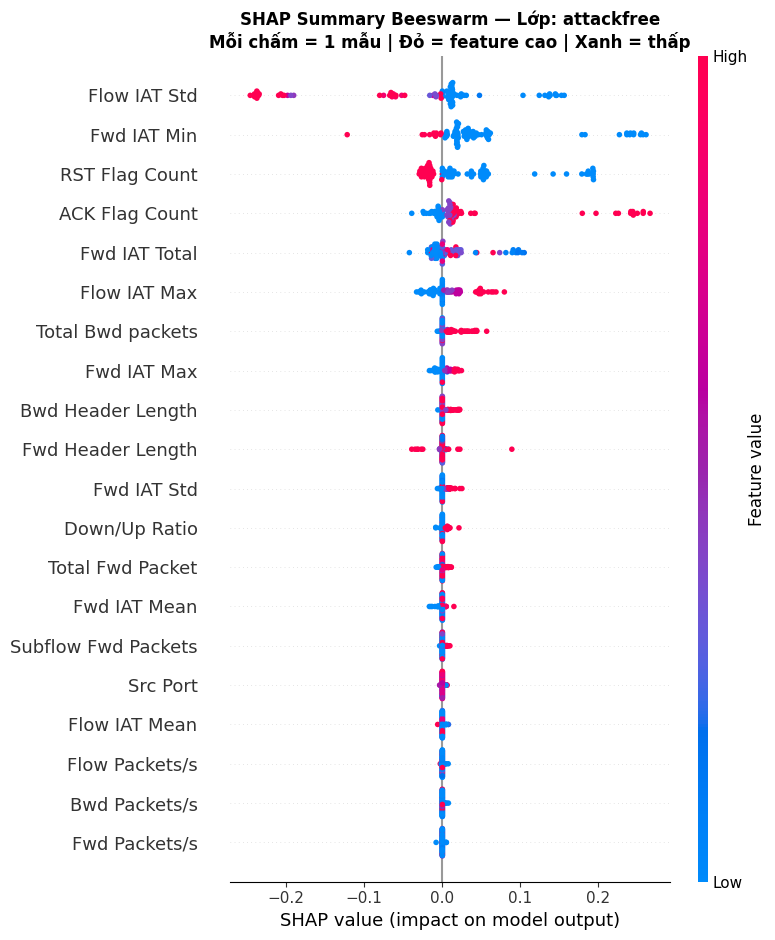


Top 10 features (SHAP): ['Fwd IAT Min', 'Fwd Header Length', 'RST Flag Count', 'Flow IAT Std', 'ACK Flag Count', 'Fwd IAT Total', 'Fwd IAT Max', 'Flow IAT Max', 'Total Fwd Packet', 'Total Bwd packets']


In [16]:
# ── 3.1 SHAP Global — Beeswarm (dùng 1 lớp) ──
target_cls = 0  # attackfree

plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_values_by_class[target_cls],  # (88, 78) ✓
    X_shap,                            # (88, 78) ✓
    feature_names=feature_names,
    max_display=20,
    plot_type='dot',
    show=False
)
plt.title(f'SHAP Summary Beeswarm — Lớp: {label_names[target_cls]}\n'
          f'Mỗi chấm = 1 mẫu | Đỏ = feature cao | Xanh = thấp',
          fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(data_dir + 'shap_global_beeswarm.png', dpi=300, bbox_inches='tight')
print('✓ Đã lưu: shap_global_beeswarm.png')
plt.show()

# ── Tính top10 SHAP để dùng ở Phần 6 ──
shap_sorted_idx = np.argsort(mean_shap_global)[::-1]
top10_shap = [feature_names[i] for i in shap_sorted_idx[:10]]
print(f'\nTop 10 features (SHAP): {top10_shap}')

✓ Đã lưu: shap_global_bar.png

Top 10 features (SHAP): ['Fwd IAT Min', 'Fwd Header Length', 'RST Flag Count', 'Flow IAT Std', 'ACK Flag Count', 'Fwd IAT Total', 'Fwd IAT Max', 'Flow IAT Max', 'Total Fwd Packet', 'Total Bwd packets']


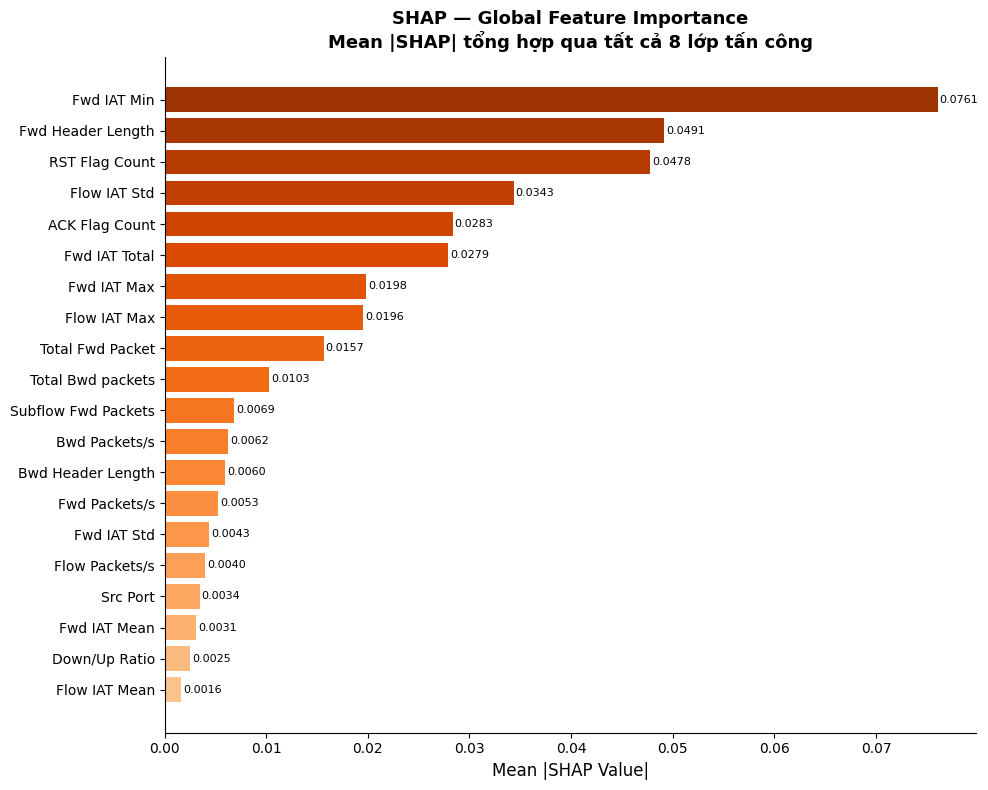

In [15]:
# ── 3.2 SHAP Global — Bar plot tổng hợp tất cả lớp ──
mean_shap_global = np.mean(
    [np.abs(shap_values_by_class[i]).mean(axis=0) for i in range(n_classes)],
    axis=0
)  # shape: (78,) ✓

shap_sorted_idx = np.argsort(mean_shap_global)[::-1]
top10_shap      = [feature_names[i] for i in shap_sorted_idx[:10]]

top_k  = 20
top_scores_shap = mean_shap_global[shap_sorted_idx[:top_k]][::-1]
top_labels_shap = [feature_names[i] for i in shap_sorted_idx[:top_k]][::-1]

fig, ax = plt.subplots(figsize=(10, 8))
colors_shap = plt.cm.Oranges(np.linspace(0.3, 0.9, top_k))
bars = ax.barh(range(top_k), top_scores_shap, color=colors_shap)
ax.set_yticks(range(top_k))
ax.set_yticklabels(top_labels_shap, fontsize=10)
ax.set_xlabel('Mean |SHAP Value|', fontsize=12)
ax.set_title('SHAP — Global Feature Importance\n'
             'Mean |SHAP| tổng hợp qua tất cả 8 lớp tấn công',
             fontsize=13, fontweight='bold')
for bar, val in zip(bars, top_scores_shap):
    ax.text(val + 0.0002, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(data_dir + 'shap_global_bar.png', dpi=300, bbox_inches='tight')
print('✓ Đã lưu: shap_global_bar.png')
print(f'\nTop 10 features (SHAP): {top10_shap}')
plt.show()

---
## 📊 PHẦN 4: SHAP Per-class Explanation

Câu hỏi: *"Feature nào quan trọng khi mô hình nhận dạng từng loại tấn công cụ thể?"*  
→ Giúp hiểu **đặc trưng phân biệt** của từng loại tấn công trong giao thức IEC 104.

✓ Đã lưu: shap_per_class_heatmap.png


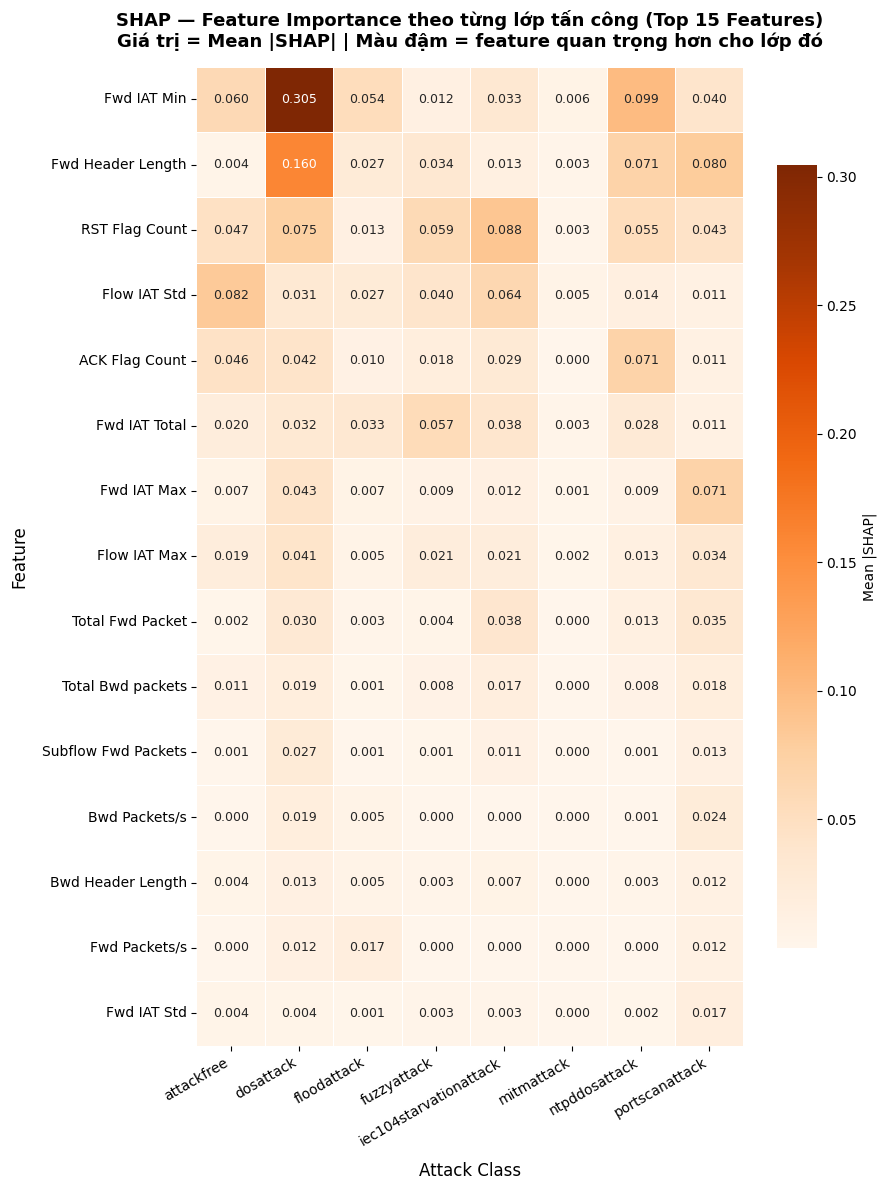

In [17]:
top_k_heatmap = 15
shap_class_matrix = np.zeros((n_classes, top_k_heatmap))
for cls_idx in range(n_classes):
    mean_abs = np.abs(shap_values_by_class[cls_idx]).mean(axis=0)
    shap_class_matrix[cls_idx] = mean_abs[shap_sorted_idx[:top_k_heatmap]]

feat_labels_shap = [feature_names[i][:22] for i in shap_sorted_idx[:top_k_heatmap]]

fig, ax = plt.subplots(figsize=(9, 12))  # đổi sang dọc

sns.heatmap(
    shap_class_matrix.T,             # xoay 90°
    annot=True,
    fmt='.3f',
    annot_kws={'size': 9},
    xticklabels=label_names,         # lớp tấn công trên trục X
    yticklabels=feat_labels_shap,    # features trên trục Y
    cmap='Oranges',                  # giữ nguyên
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'shrink': 0.8, 'label': 'Mean |SHAP|'},
    ax=ax
)

ax.set_title(
    'SHAP — Feature Importance theo từng lớp tấn công (Top 15 Features)\n'
    'Giá trị = Mean |SHAP| | Màu đậm = feature quan trọng hơn cho lớp đó',
    fontsize=13, fontweight='bold', pad=14
)
ax.set_xlabel('Attack Class', fontsize=12, labelpad=10)
ax.set_ylabel('Feature', fontsize=12, labelpad=10)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right', fontsize=10)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=10)

plt.tight_layout()
plt.savefig(data_dir + 'shap_per_class_heatmap.png', dpi=300, bbox_inches='tight')
print('✓ Đã lưu: shap_per_class_heatmap.png')
plt.show()

✓ Đã lưu: shap_per_class_subplots.png


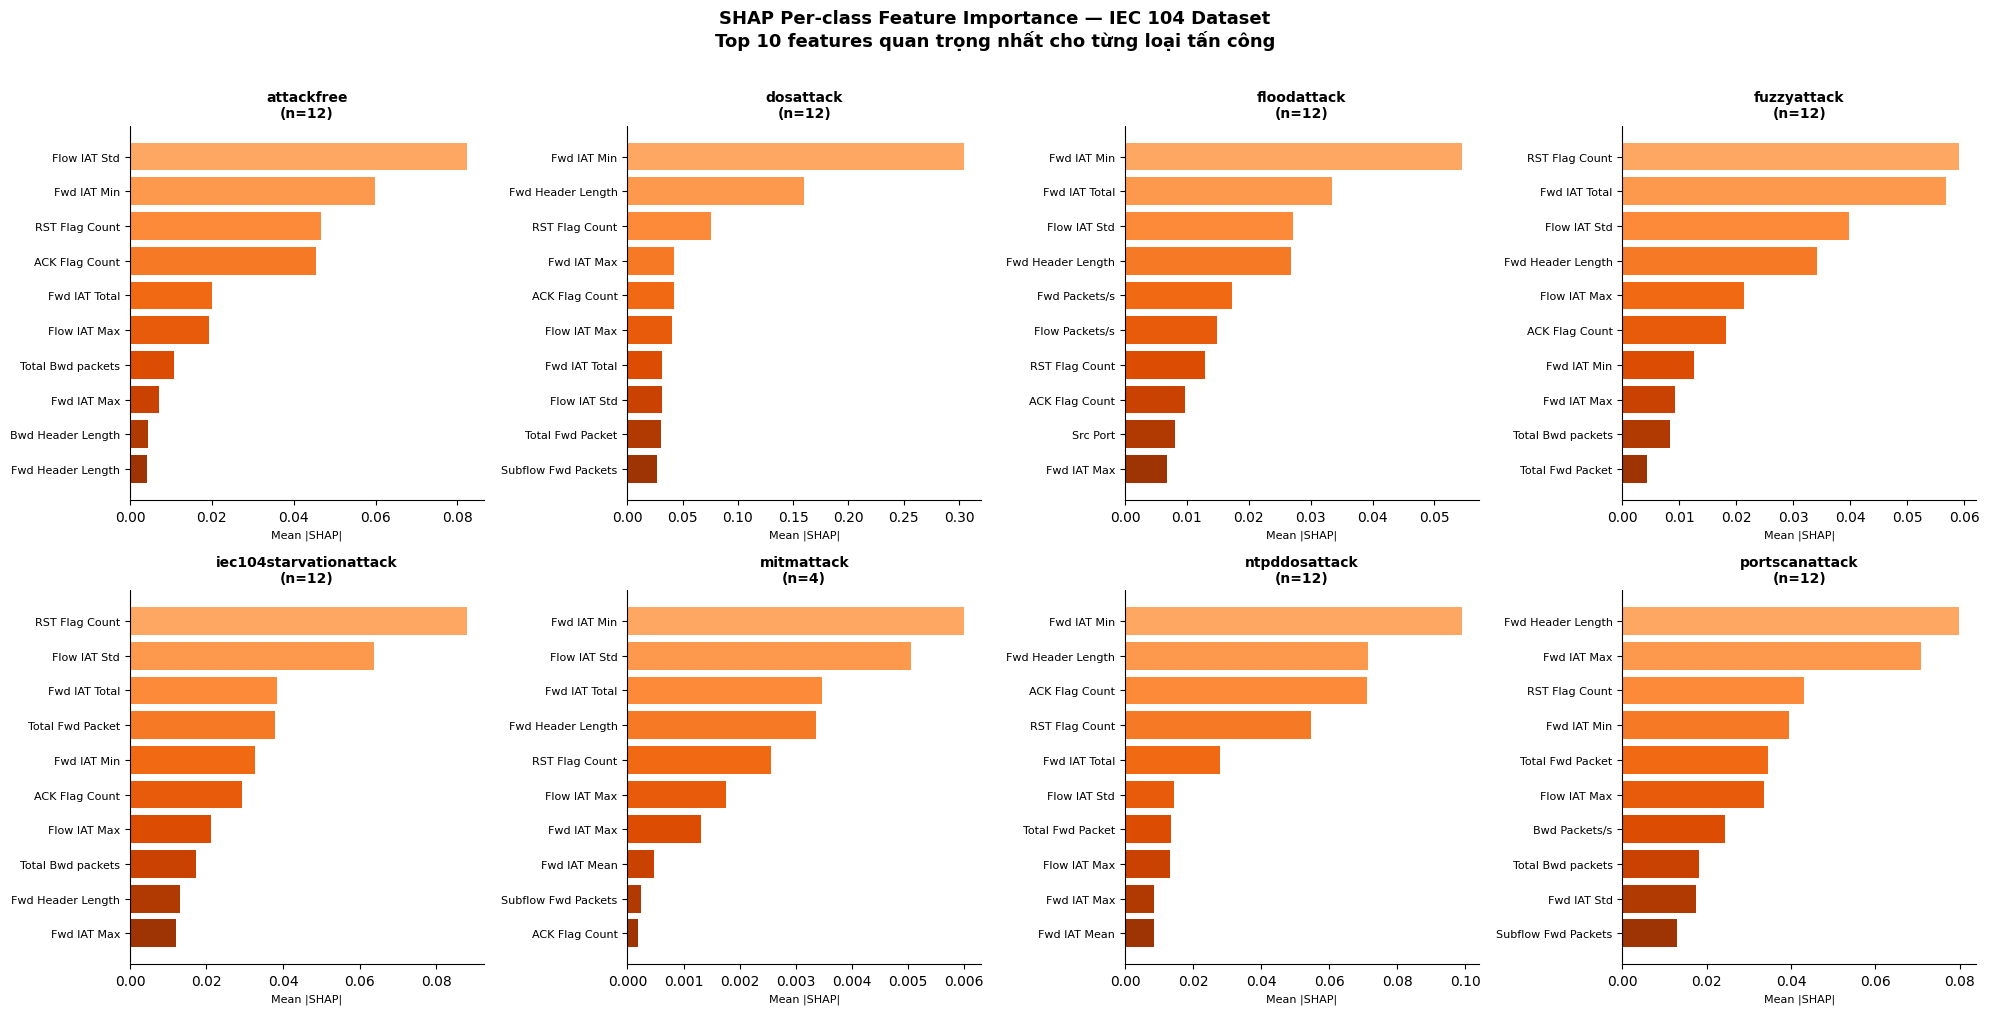

In [18]:
# -----------------------------------------------
# 4.2 Bar chart riêng từng lớp — 8 subplots
#
# Mỗi subplot = 1 lớp tấn công
# → Rõ ràng hơn khi cần phân tích từng lớp
# → Dùng trực tiếp trong Chương 4 luận văn
# -----------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for cls_idx, cls_name in enumerate(label_names):
    ax = axes[cls_idx]
    mean_abs = np.abs(shap_values_by_class[cls_idx]).mean(axis=0)
    top_idx  = np.argsort(mean_abs)[::-1][:10]

    # Màu gradient: đậm nhất = quan trọng nhất
    bar_colors = plt.cm.Oranges(np.linspace(0.4, 0.9, 10))[::-1]
    ax.barh(
        range(10),
        mean_abs[top_idx][::-1],
        color=bar_colors
    )
    ax.set_yticks(range(10))
    ax.set_yticklabels(
        [feature_names[i][:20] for i in top_idx[::-1]], fontsize=8
    )
    n_samples_cls = np.sum(y_shap == cls_idx)
    ax.set_title(f'{cls_name}\n(n={n_samples_cls})', fontsize=10, fontweight='bold')
    ax.set_xlabel('Mean |SHAP|', fontsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('SHAP Per-class Feature Importance — IEC 104 Dataset\n'
             'Top 10 features quan trọng nhất cho từng loại tấn công',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(data_dir + 'shap_per_class_subplots.png', dpi=300, bbox_inches='tight')
print('✓ Đã lưu: shap_per_class_subplots.png')
plt.show()

---
## 🔬 PHẦN 5: SHAP Local Explanation — Giải thích từng mẫu cụ thể

**Local explanation** = giải thích TẠI SAO mô hình dự đoán **1 mẫu cụ thể** là lớp X.  
Đây là điểm mạnh của XAI so với mô hình black-box truyền thống.

2 loại biểu đồ:
- **Waterfall plot**: Thấy từng feature đẩy output lên (+) hoặc xuống (-)
- **Force plot**: Tổng quan trực quan hơn, dùng tốt trong báo cáo

  0%|          | 0/1 [00:00<?, ?it/s]

  Thời gian SHAP cho 1 mẫu đơn (dosattack): 14.10s
✓ Đã lưu: shap_waterfall_dosattack.png


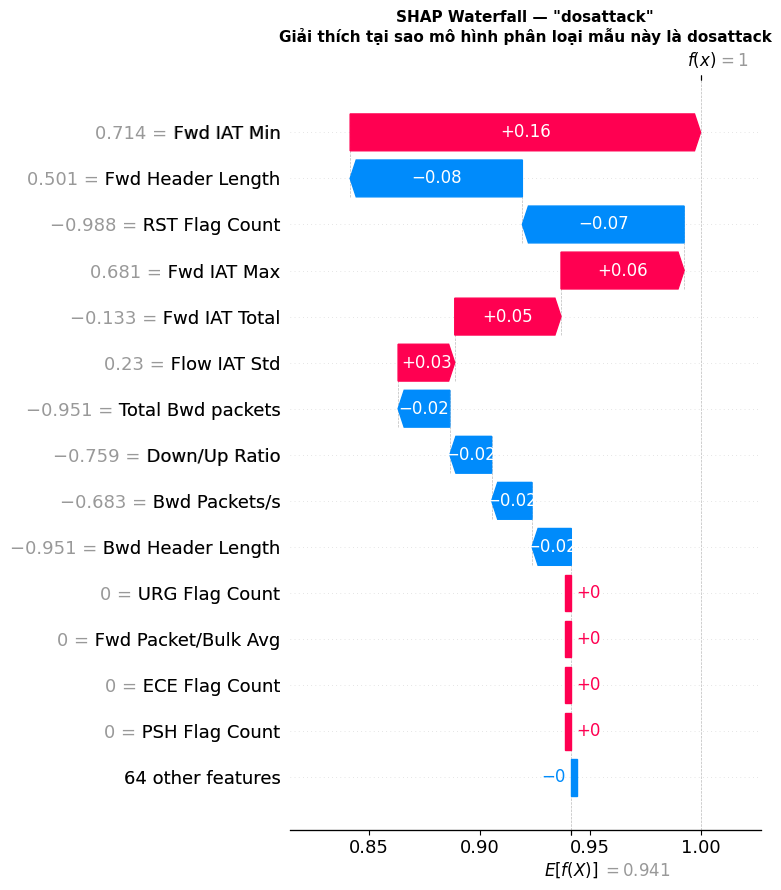

  0%|          | 0/1 [00:00<?, ?it/s]

  Thời gian SHAP cho 1 mẫu đơn (mitmattack): 13.77s
✓ Đã lưu: shap_waterfall_mitmattack.png


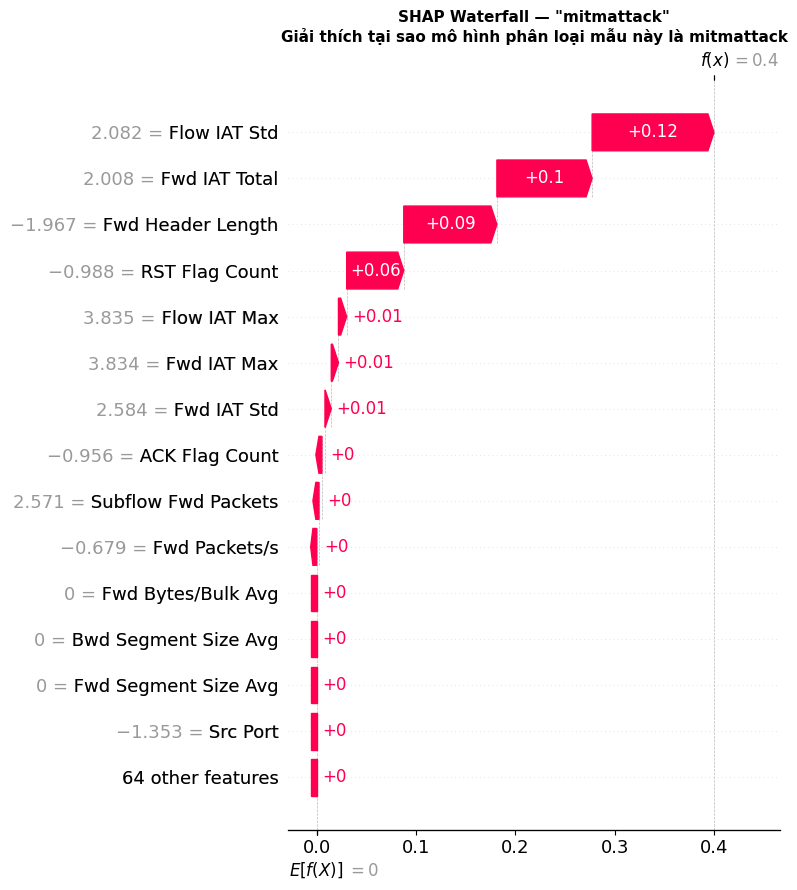

  0%|          | 0/1 [00:00<?, ?it/s]

  Thời gian SHAP cho 1 mẫu đơn (portscanattack): 13.74s
✓ Đã lưu: shap_waterfall_portscanattack.png


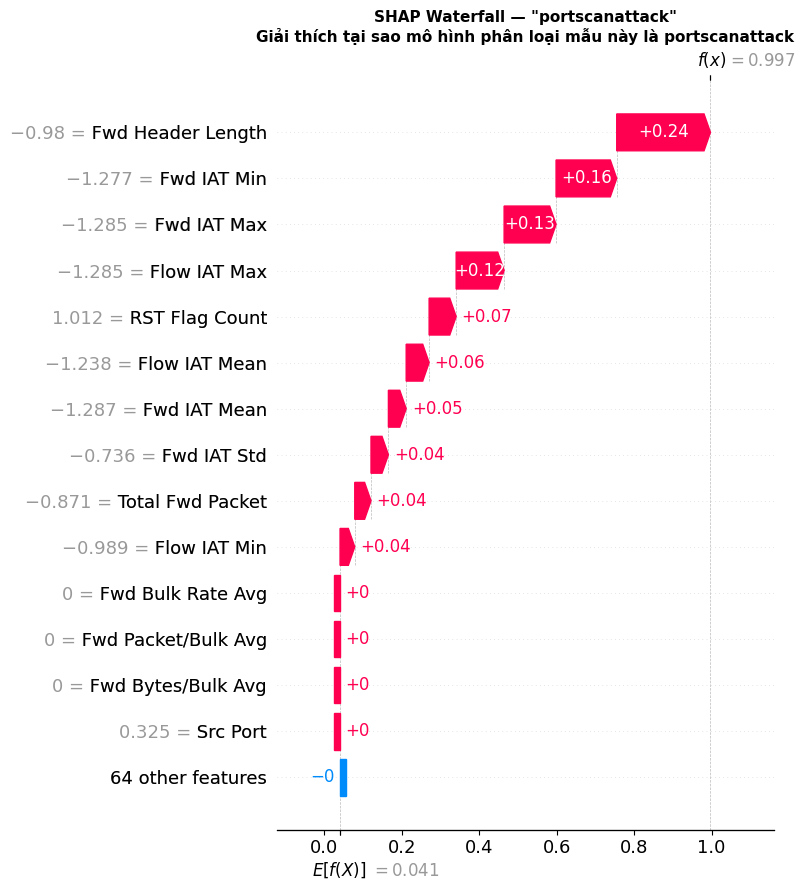

  0%|          | 0/1 [00:00<?, ?it/s]

  Thời gian SHAP cho 1 mẫu đơn (floodattack): 15.51s
✓ Đã lưu: shap_waterfall_floodattack.png


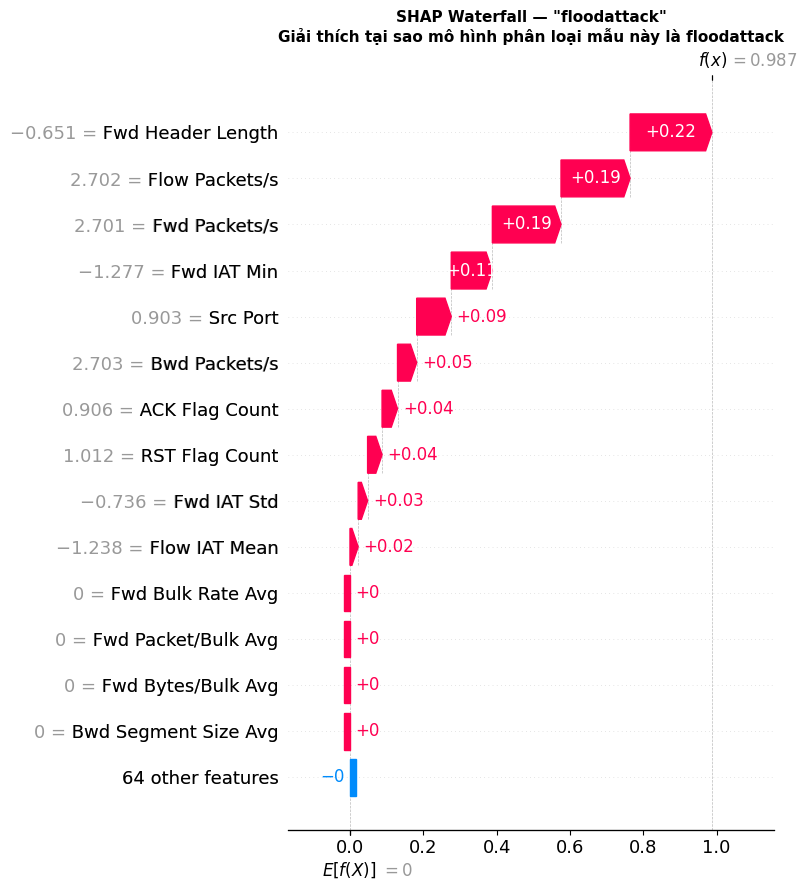

In [19]:
target_classes = ['dosattack', 'mitmattack', 'portscanattack', 'floodattack']

for cls_name in target_classes:
    cls_idx = list(label_names).index(cls_name)

    # Tìm mẫu được predict đúng
    y_pred_shap = model.predict(X_shap)
    correct_cls = np.where(
        (y_shap == cls_idx) & (y_pred_shap == cls_idx)
    )[0]

    if len(correct_cls) == 0:
        print(f'  ⚠ Không có mẫu {cls_name} predict đúng trong tập SHAP, bỏ qua.')
        continue

    sample_i = correct_cls[0]
    shap_exp = shap.Explanation(
        values        = shap_values_by_class[cls_idx][sample_i],
        base_values   = explainer.expected_value[cls_idx],
        data          = X_shap[sample_i],
        feature_names = feature_names
    )

    # --- Đo thời gian SHAP cho 1 mẫu đơn ---
    t0 = time.perf_counter()
    sv_single = explainer.shap_values(X_shap[sample_i:sample_i+1], nsamples='auto')
    single_sample_time = time.perf_counter() - t0

    if 'shap_single_sample_times' not in timing:
        timing['shap_single_sample_times'] = []
    timing['shap_single_sample_times'].append(single_sample_time)

    print(f"  Thời gian SHAP cho 1 mẫu đơn ({cls_name}): {single_sample_time:.2f}s")

    # --- Vẽ waterfall như cũ ---
    plt.figure(figsize=(10, 6))
    shap.waterfall_plot(shap_exp, max_display=15, show=False)
    plt.title(f'SHAP Waterfall — "{cls_name}"\n'
              f'Giải thích tại sao mô hình phân loại mẫu này là {cls_name}',
              fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.savefig(data_dir + f'shap_waterfall_{cls_name}.png', dpi=300, bbox_inches='tight')
    print(f'✓ Đã lưu: shap_waterfall_{cls_name}.png')
    plt.show()

In [20]:
# ==============================================================================
# LIME ĐỐI SÁNH VỚI SHAP (LOCAL EXPLANATION)
# Dán vào TABNET_XAI_LUANVAN_v2.ipynb, NGAY SAU cell 21 (SHAP local waterfall)
# Chỉ áp dụng ở mức LOCAL — dùng lại đúng 4 mẫu đã chọn ở cell 21:
#   dosattack, mitmattack, portscanattack, floodattack
# ==============================================================================

# Cần cài (chạy 1 lần):
# import sys
# !{sys.executable} -m pip install lime

import time
import json
import numpy as np
from lime.lime_tabular import LimeTabularExplainer

# --- 1. Khởi tạo LIME explainer — dùng chính tập train đã có ---
lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=feature_names,
    class_names=label_names,
    mode='classification',
    discretize_continuous=True,
    random_state=42
)

# --- 2. Danh sách lớp cần giải thích — TRÙNG với target_classes ở cell 21 ---
target_classes = ['dosattack', 'mitmattack', 'portscanattack', 'floodattack']
top_k = 10

comparison_results = {}
lime_times = []

for cls_name in target_classes:
    cls_idx = list(label_names).index(cls_name)

    # Tìm 1 mẫu dự đoán ĐÚNG cho lớp này trong tập X_shap (giống logic cell 21)
    y_pred_shap = model.predict(X_shap)
    correct_cls = np.where((y_shap == cls_idx) & (y_pred_shap == cls_idx))[0]

    if len(correct_cls) == 0:
        print(f'⚠ Không có mẫu {cls_name} dự đoán đúng trong tập SHAP, bỏ qua.')
        continue

    sample_i = correct_cls[0]
    sample_x = X_shap[sample_i]

    # --- Giải thích bằng LIME ---
    t0 = time.perf_counter()
    lime_exp = lime_explainer.explain_instance(
        data_row=sample_x,
        predict_fn=model.predict_proba,
        num_features=top_k,
        labels=[cls_idx]
    )
    lime_time = time.perf_counter() - t0
    lime_times.append(lime_time)

    # Trích top-K feature theo LIME — lấy tên feature gốc từ chuỗi điều kiện
    lime_pairs = lime_exp.as_list(label=cls_idx)
    lime_top_features = []
    for feat_str, weight in lime_pairs:
        for fname in feature_names:
            if fname in feat_str:
                lime_top_features.append(fname)
                break
    lime_top_features = lime_top_features[:top_k]

    # --- Top-K feature theo SHAP CHO CÙNG mẫu này (không phải global) ---
    shap_vals_sample = shap_values_by_class[cls_idx][sample_i]
    shap_top_idx = np.argsort(np.abs(shap_vals_sample))[::-1][:top_k]
    shap_top_features = [feature_names[i] for i in shap_top_idx]

    overlap = set(lime_top_features) & set(shap_top_features)
    overlap_pct = len(overlap) / top_k * 100

    print(f'\n=== {cls_name} (mẫu #{sample_i}) ===')
    print(f'  LIME top-{top_k}: {lime_top_features}')
    print(f'  SHAP top-{top_k}: {shap_top_features}')
    print(f'  Overlap: {len(overlap)}/{top_k} ({overlap_pct:.0f}%) — {sorted(overlap)}')
    print(f'  Thời gian LIME cho 1 mẫu: {lime_time:.2f}s')

    # Lưu hình LIME (cùng style waterfall của SHAP để đặt cạnh nhau trong luận văn)
    fig = lime_exp.as_pyplot_figure(label=cls_idx)
    fig.suptitle(f'LIME Explanation — "{cls_name}" (mẫu #{sample_i})', fontsize=11)
    fig.tight_layout()
    fig.savefig(data_dir + f'lime_{cls_name}.png', dpi=300, bbox_inches='tight')
    print(f'  ✓ Đã lưu: lime_{cls_name}.png')

    comparison_results[cls_name] = {
        'sample_index': int(sample_i),
        'lime_top_features': lime_top_features,
        'shap_top_features': shap_top_features,
        'overlap_features': sorted(overlap),
        'overlap_count': len(overlap),
        'overlap_pct': overlap_pct,
        'lime_time_sec': round(lime_time, 3),
    }


# --- 3. Tổng hợp và lưu kết quả ---
print(f"\n{'='*70}")
print("TỔNG HỢP OVERLAP LIME vs SHAP")
print(f"{'='*70}")

overlaps = [r['overlap_pct'] for r in comparison_results.values()]
print(f"Overlap trung bình qua {len(overlaps)} mẫu: {np.mean(overlaps):.1f}%")
print(f"Thời gian LIME trung bình/mẫu: {np.mean(lime_times):.2f}s")

with open(data_dir + 'lime_shap_comparison.json', 'w', encoding='utf-8') as f:
    json.dump(comparison_results, f, indent=4, ensure_ascii=False)
print(f"\n✓ Đã lưu: {data_dir}lime_shap_comparison.json")

# So sánh với Overlap@10 giữa Attention và SHAP đã có (mục 3.7.1 / 4.3 luận văn)
print(f"\nSo sánh mức đồng thuận:")
print(f"  Attention vs SHAP (global, đã có):  Overlap@10 = 70%, Spearman ρ = 0.64")
print(f"  LIME vs SHAP (local, mẫu này):      Overlap trung bình = {np.mean(overlaps):.1f}%")


=== dosattack (mẫu #12) ===
  LIME top-10: ['Total Fwd Packet', 'Fwd IAT Min', 'RST Flag Count', 'Fwd IAT Total', 'Src Port', 'Flow IAT Max', 'ACK Flag Count', 'Fwd Header Length', 'Down/Up Ratio', 'Flow IAT Std']
  SHAP top-10: ['Fwd IAT Min', 'Fwd Header Length', 'RST Flag Count', 'Fwd IAT Max', 'Fwd IAT Total', 'Flow IAT Std', 'Total Bwd packets', 'Down/Up Ratio', 'Bwd Packets/s', 'Bwd Header Length']
  Overlap: 6/10 (60%) — ['Down/Up Ratio', 'Flow IAT Std', 'Fwd Header Length', 'Fwd IAT Min', 'Fwd IAT Total', 'RST Flag Count']
  Thời gian LIME cho 1 mẫu: 1.44s
  ✓ Đã lưu: lime_dosattack.png

=== mitmattack (mẫu #61) ===
  LIME top-10: ['Flow IAT Std', 'Fwd IAT Total', 'RST Flag Count', 'Flow IAT Max', 'Fwd IAT Max', 'Flow Duration', 'Fwd IAT Min', 'Subflow Fwd Packets', 'Fwd IAT Mean', 'Total Bwd packets']
  SHAP top-10: ['Flow IAT Std', 'Fwd IAT Total', 'Fwd Header Length', 'RST Flag Count', 'Flow IAT Max', 'Fwd IAT Max', 'Fwd IAT Std', 'ACK Flag Count', 'Subflow Fwd Packets', 'F

✓ Đã lưu: shap_force_dosattack.png


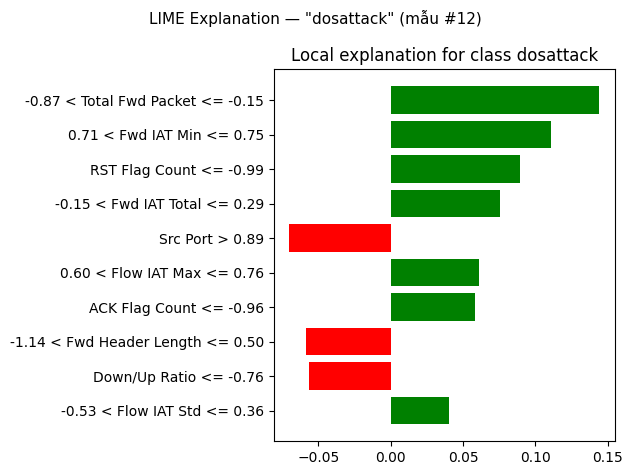

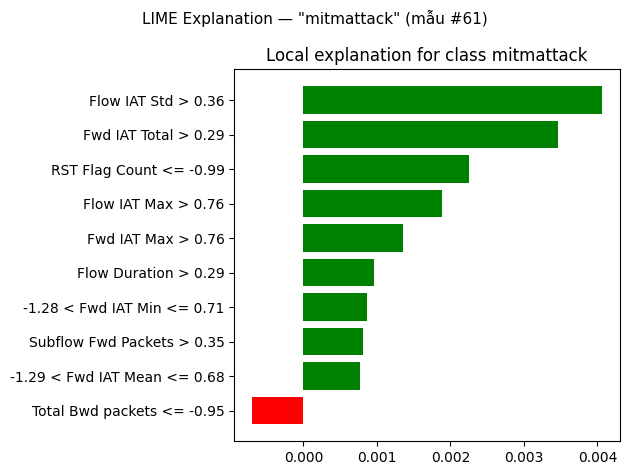

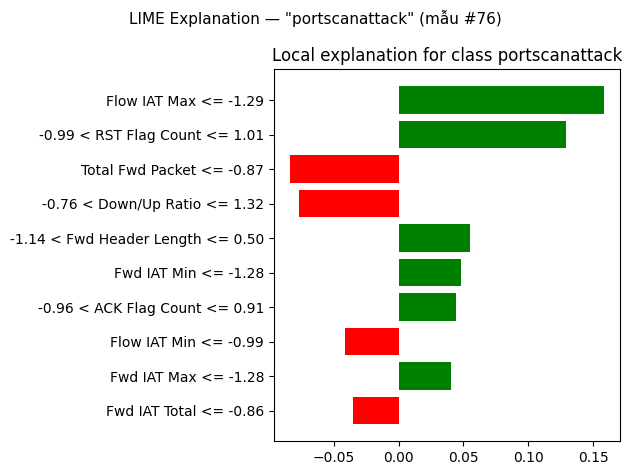

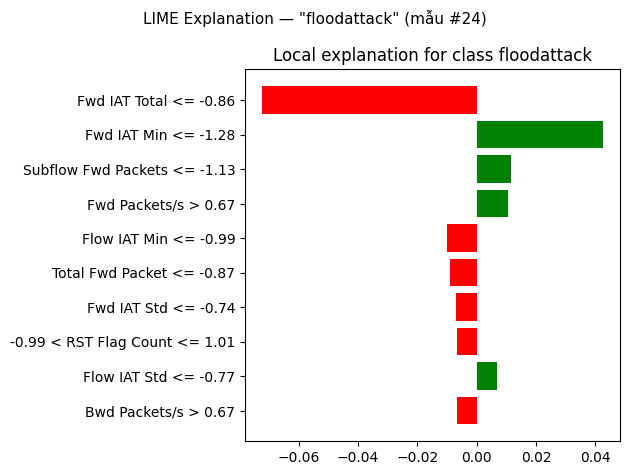

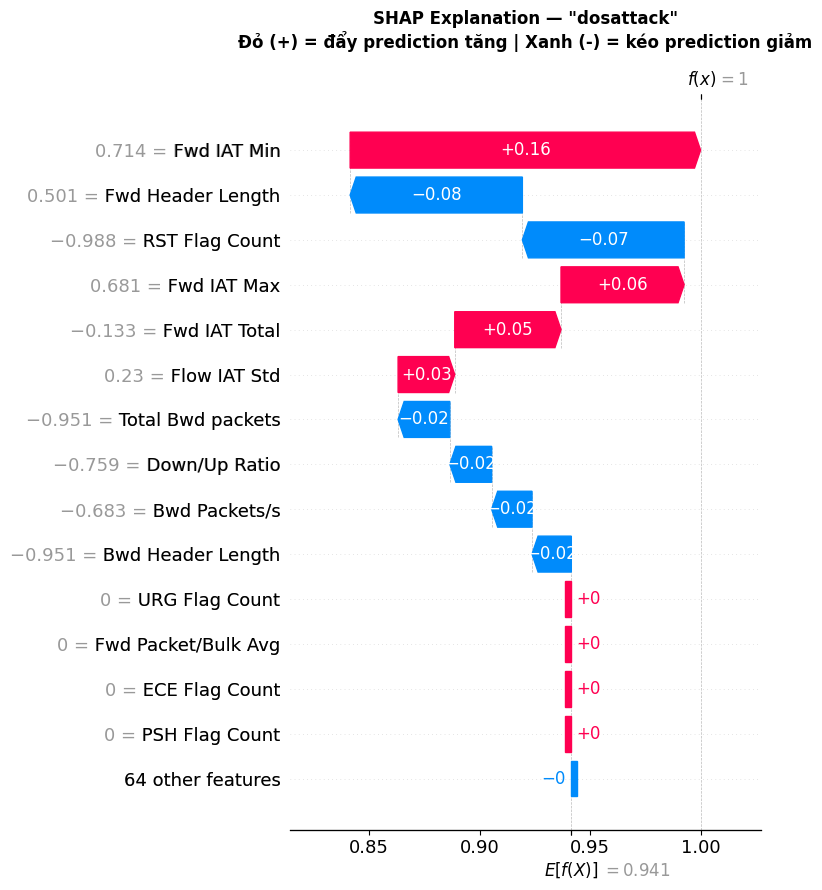

✓ Đã lưu: shap_force_mitmattack.png


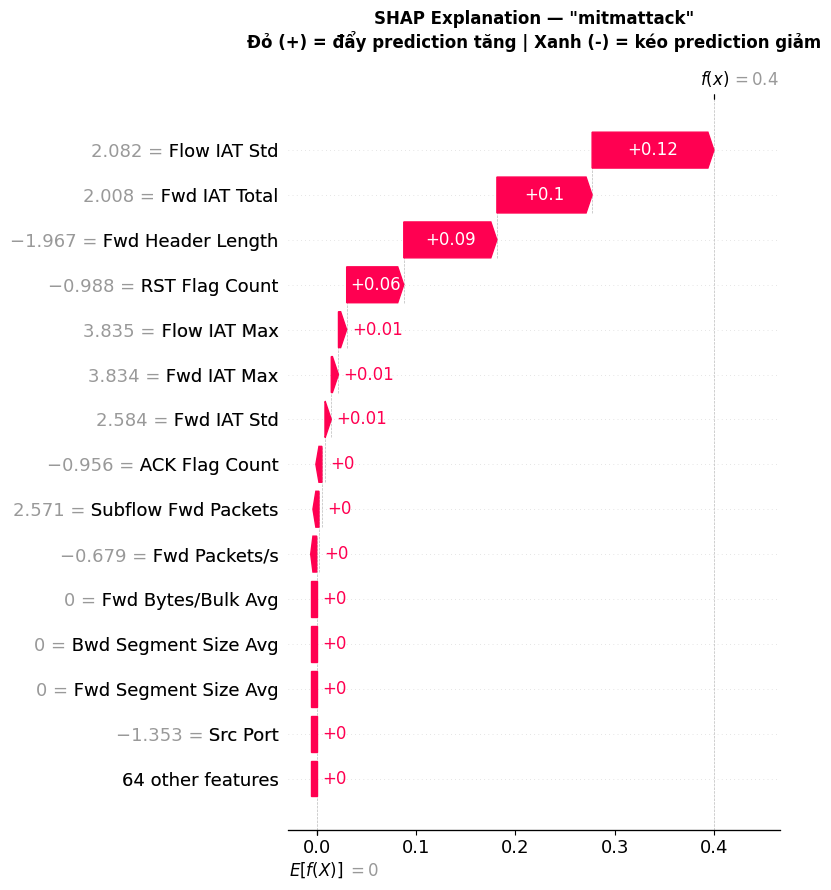

In [21]:
# -----------------------------------------------
# 5.2 Force Plot — dosattack và mitmattack
# -----------------------------------------------
for cls_name in ['dosattack', 'mitmattack']:
    cls_idx     = list(label_names).index(cls_name)
    y_pred_shap = model.predict(X_shap)
    correct_cls = np.where(
        (y_shap == cls_idx) & (y_pred_shap == cls_idx)
    )[0]

    if len(correct_cls) == 0:
        print(f'⚠ Không có mẫu {cls_name} predict đúng')
        continue

    sample_i   = correct_cls[0]
    sv         = shap_values_by_class[cls_idx][sample_i]   # (n_features,)
    base_val   = explainer.expected_value[cls_idx]
    feat_vals  = X_shap[sample_i]

    # ── Thay force_plot bằng waterfall — đẹp và rõ hơn nhiều ──
    # Waterfall không bị vấn đề layout như force_plot matplotlib
    shap_exp = shap.Explanation(
        values        = sv,
        base_values   = base_val,
        data          = feat_vals,
        feature_names = feature_names
    )

    plt.figure(figsize=(12, 7))
    shap.waterfall_plot(shap_exp, max_display=15, show=False)
    plt.title(f'SHAP Explanation — "{cls_name}"\n'
              f'Đỏ (+) = đẩy prediction tăng | Xanh (-) = kéo prediction giảm',
              fontsize=12, fontweight='bold', pad=15)
    plt.tight_layout()
    plt.savefig(data_dir + f'shap_force_{cls_name}.png',
                dpi=300, bbox_inches='tight')
    print(f'✓ Đã lưu: shap_force_{cls_name}.png')
    plt.show()

---
## ⚖️ PHẦN 6: So sánh 2 Tầng XAI — Attention vs SHAP

**Đây là phần độc đáo nhất của luận văn!**

Nếu Attention và SHAP **đồng thuận** về top features → Kết luận đáng tin cậy  
Nếu **khác nhau** → Cơ hội phân tích sâu: tại sao 2 phương pháp bất đồng?  
(Có thể do Attention = process explanation, SHAP = output explanation)

In [22]:
# -----------------------------------------------
# 6.1 Bảng so sánh Top 10 — Attention vs SHAP
# -----------------------------------------------
overlap_set = set(top10_attention) & set(top10_shap)
overlap_n   = len(overlap_set)

print('=' * 65)
print(f'{"Rank":<6} {"TabNet Attention (Intrinsic)":<30} {"SHAP (Post-hoc)":<25}')
print('=' * 65)
for rank, (att, shp) in enumerate(zip(top10_attention, top10_shap), 1):
    match = '✓' if att in overlap_set and shp in overlap_set else ' '
    print(f'{rank:<6} {att:<30} {match}  {shp:<25}')
print('=' * 65)
print(f'\nOverlap@10: {overlap_n}/10 features trùng nhau ({overlap_n*10}%)')
print(f'Features trùng: {list(overlap_set)}')
if overlap_n >= 7:
    print('→ Đánh giá: Hai phương pháp ĐỒNG THUẬN CAO → Kết quả đáng tin cậy')
elif overlap_n >= 4:
    print('→ Đánh giá: Đồng thuận TRUNG BÌNH → Một số features có vai trò khác nhau')
else:
    print('→ Đánh giá: Có sự KHÁC BIỆT đáng kể → Cần phân tích thêm trong luận văn')

Rank   TabNet Attention (Intrinsic)   SHAP (Post-hoc)          
1      Fwd Header Length              ✓  Fwd IAT Min              
2      Fwd IAT Min                    ✓  Fwd Header Length        
3      Bwd Header Length                 RST Flag Count           
4      Flow IAT Std                   ✓  Flow IAT Std             
5      RST Flag Count                    ACK Flag Count           
6      Flow IAT Min                      Fwd IAT Total            
7      Total Fwd Packet                  Fwd IAT Max              
8      Fwd IAT Total                     Flow IAT Max             
9      Down/Up Ratio                     Total Fwd Packet         
10     Fwd Packets/s                     Total Bwd packets        

Overlap@10: 6/10 features trùng nhau (60%)
Features trùng: ['Fwd Header Length', 'Flow IAT Std', 'RST Flag Count', 'Total Fwd Packet', 'Fwd IAT Total', 'Fwd IAT Min']
→ Đánh giá: Đồng thuận TRUNG BÌNH → Một số features có vai trò khác nhau


✓ Đã lưu: xai_attention_vs_shap.png


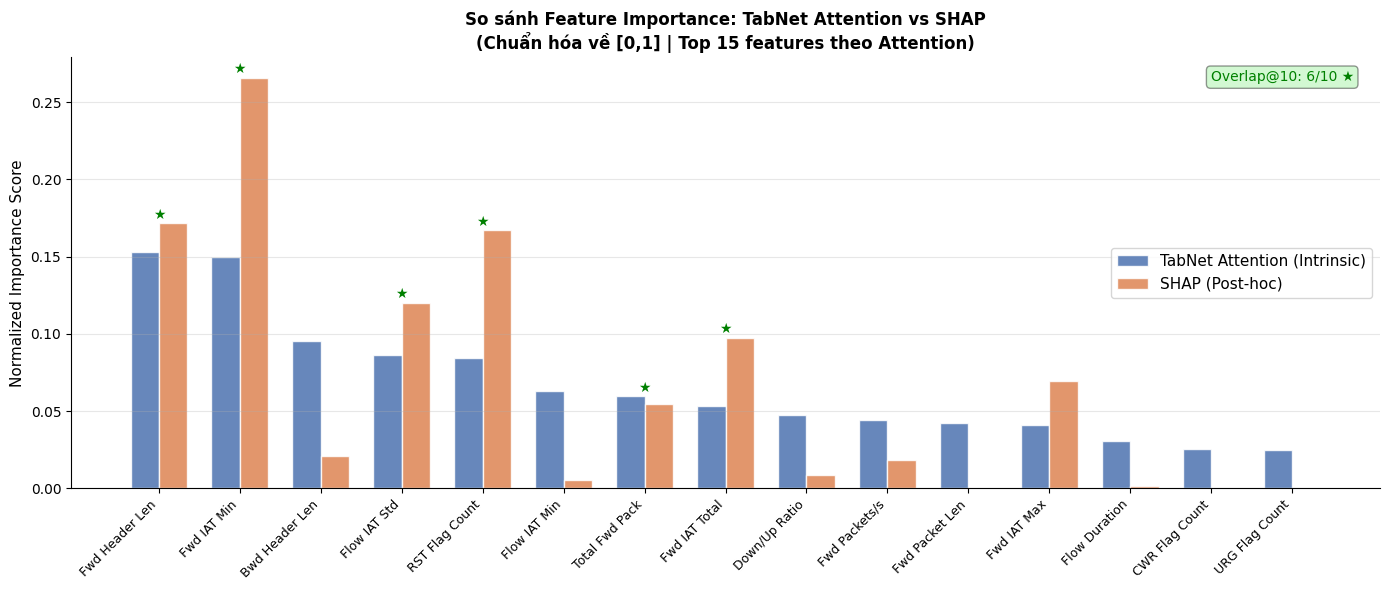

In [23]:
# -----------------------------------------------
# 6.2 Biểu đồ so sánh Attention vs SHAP
#
# Chuẩn hóa cả 2 về [0,1] để so sánh cùng thang đo
# → Dùng trực tiếp trong báo cáo luận văn
# -----------------------------------------------
top_k_cmp = 15

# Lấy top 15 theo Attention
att_scores  = feat_imp[sorted_idx[:top_k_cmp]]
att_labels  = [feature_names[i] for i in sorted_idx[:top_k_cmp]]
att_norm    = att_scores / att_scores.sum()

# SHAP scores cho cùng top 15 features
shap_scores = mean_shap_global[sorted_idx[:top_k_cmp]]
shap_norm   = shap_scores / shap_scores.sum()

x     = np.arange(top_k_cmp)
width = 0.35

fig, ax = plt.subplots(figsize=(14, 6))
b1 = ax.bar(x - width/2, att_norm,  width, label='TabNet Attention (Intrinsic)',
            color='#4C72B0', alpha=0.85, edgecolor='white')
b2 = ax.bar(x + width/2, shap_norm, width, label='SHAP (Post-hoc)',
            color='#DD8452', alpha=0.85, edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels([f[:14] for f in att_labels], rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Normalized Importance Score', fontsize=11)
ax.set_title('So sánh Feature Importance: TabNet Attention vs SHAP\n'
             '(Chuẩn hóa về [0,1] | Top 15 features theo Attention)',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Đánh dấu features trùng nhau bằng dấu ★
for i, label in enumerate(att_labels):
    if label in overlap_set:
        ax.text(i, max(att_norm[i], shap_norm[i]) + 0.003, '★',
                ha='center', fontsize=10, color='green')

ax.text(0.98, 0.97, f'Overlap@10: {overlap_n}/10 ★',
        transform=ax.transAxes, ha='right', va='top',
        fontsize=10, color='green',
        bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.4))

plt.tight_layout()
plt.savefig(data_dir + 'xai_attention_vs_shap.png', dpi=300, bbox_inches='tight')
print('✓ Đã lưu: xai_attention_vs_shap.png')
plt.show()

✓ Đã lưu: xai_correlation_scatter.png

Spearman correlation: r = 0.6400, p = 2.8117e-10
→ Tương quan TRUNG BÌNH: Có sự bổ sung giữa 2 phương pháp


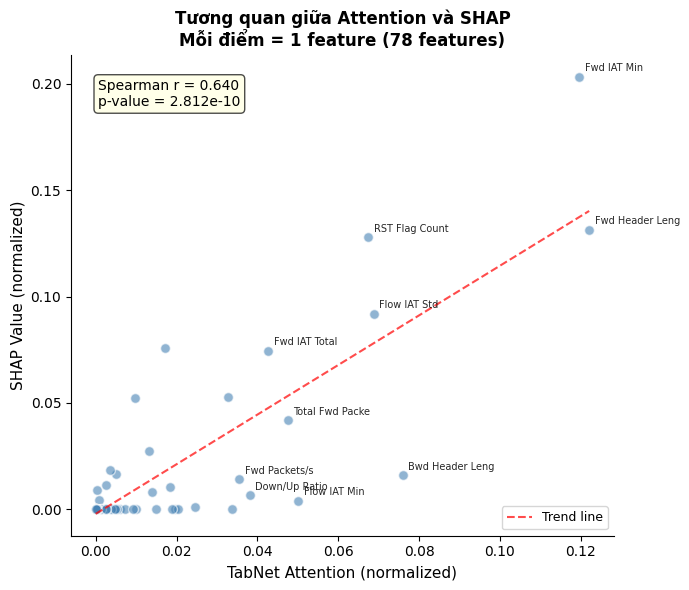

In [24]:
# -----------------------------------------------
# 6.3 Scatter plot tương quan Attention vs SHAP
#
# Nếu điểm nằm gần đường y=x → 2 phương pháp đồng thuận
# Điểm lệch xa → feature có vai trò khác nhau
#   trong 2 góc nhìn giải thích
# -----------------------------------------------
from scipy.stats import spearmanr

att_all  = feat_imp  # Tất cả features
shap_all = mean_shap_global

# Chuẩn hóa
att_norm_all  = att_all  / att_all.sum()
shap_norm_all = shap_all / shap_all.sum()

corr, pval = spearmanr(att_norm_all, shap_norm_all)

fig, ax = plt.subplots(figsize=(7, 6))
scatter = ax.scatter(
    att_norm_all, shap_norm_all,
    alpha=0.6, s=50, c='steelblue', edgecolors='white'
)

# Đánh nhãn top 10 features
for i in sorted_idx[:10]:
    ax.annotate(
        feature_names[i][:15],
        (att_norm_all[i], shap_norm_all[i]),
        fontsize=7, alpha=0.85,
        xytext=(4, 4), textcoords='offset points'
    )

# Đường hồi quy
z = np.polyfit(att_norm_all, shap_norm_all, 1)
p = np.poly1d(z)
x_line = np.linspace(att_norm_all.min(), att_norm_all.max(), 100)
ax.plot(x_line, p(x_line), 'r--', alpha=0.7, linewidth=1.5, label='Trend line')

ax.set_xlabel('TabNet Attention (normalized)', fontsize=11)
ax.set_ylabel('SHAP Value (normalized)', fontsize=11)
ax.set_title('Tương quan giữa Attention và SHAP\n'
             'Mỗi điểm = 1 feature (78 features)',
             fontsize=12, fontweight='bold')
ax.text(0.05, 0.95,
        f'Spearman r = {corr:.3f}\np-value = {pval:.3e}',
        transform=ax.transAxes, va='top',
        bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.7),
        fontsize=10)
ax.legend(fontsize=9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(data_dir + 'xai_correlation_scatter.png', dpi=300, bbox_inches='tight')
print('✓ Đã lưu: xai_correlation_scatter.png')
print(f'\nSpearman correlation: r = {corr:.4f}, p = {pval:.4e}')
if corr >= 0.7:
    print('→ Tương quan CAO: Attention và SHAP đồng thuận mạnh')
elif corr >= 0.4:
    print('→ Tương quan TRUNG BÌNH: Có sự bổ sung giữa 2 phương pháp')
else:
    print('→ Tương quan THẤP: 2 phương pháp có góc nhìn khác biệt đáng kể')
plt.show()

---
## 📋 PHẦN 7: Tổng kết — Lưu kết quả cho Luận văn

In [26]:
import pandas as pd
import numpy as np
import pickle
import warnings
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import shap
from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.metrics import confusion_matrix, classification_report
from scipy.stats import mannwhitneyu

✓ Đã lưu: err_confusion_matrix.png


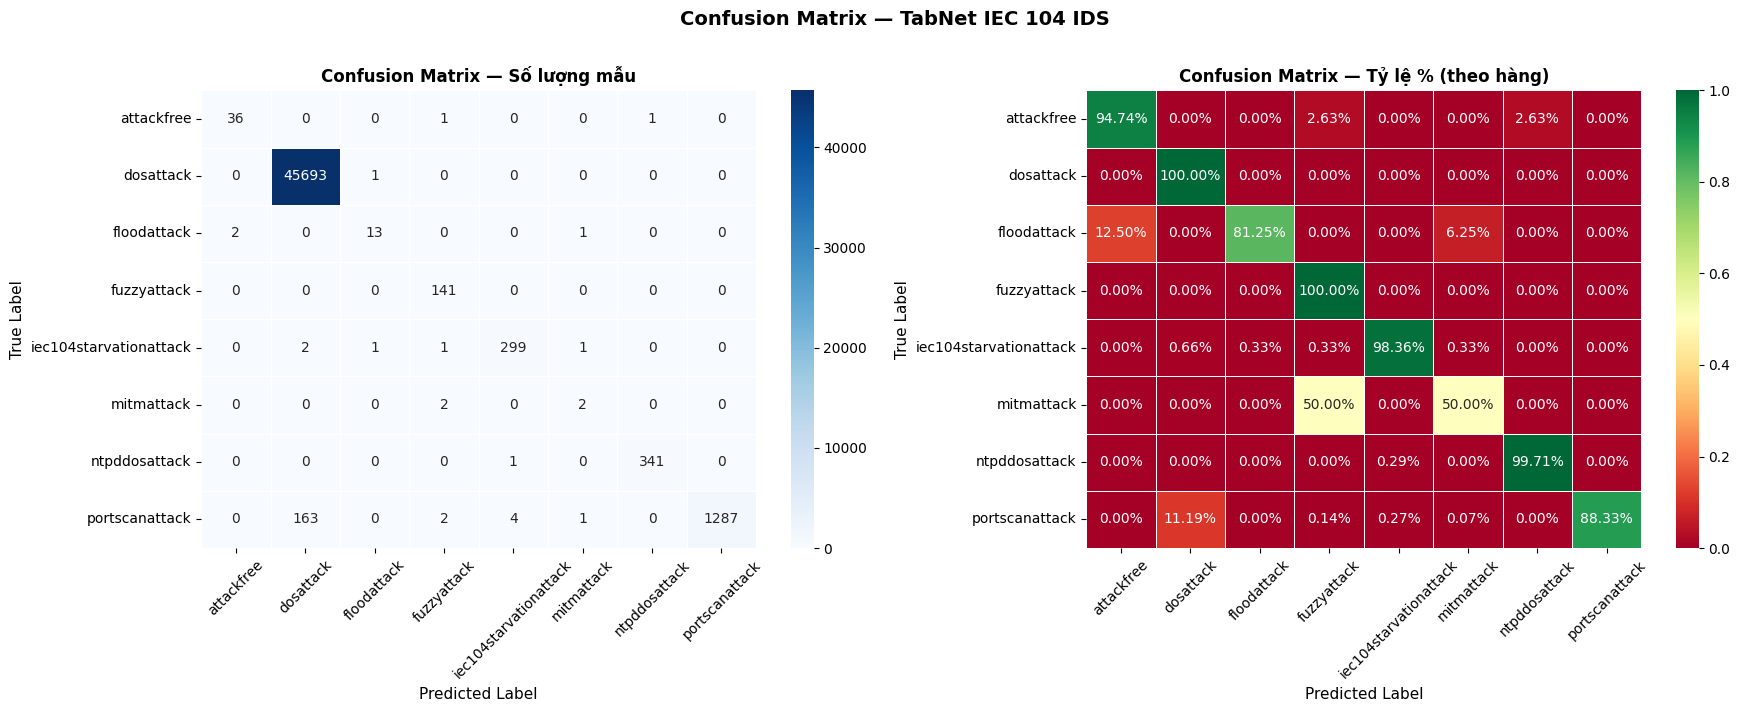

In [27]:
# -----------------------------------------------
# 7.1.1 Confusion Matrix — toàn bộ test set
#
# Đọc confusion matrix:
# - Hàng = nhãn thực (true label)
# - Cột = nhãn dự đoán (predicted label)
# - Ô [i][i] = đoán đúng (diagonal)
# - Ô [i][j] (i≠j) = lỗi: thực là i nhưng đoán là j
# -----------------------------------------------
cm = confusion_matrix(y_test, y_pred)

# Normalize theo hàng (tỷ lệ % trong mỗi lớp thực)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# --- Raw counts ---
sns.heatmap(
    cm, annot=True, fmt='d',
    xticklabels=label_names,
    yticklabels=label_names,
    cmap='Blues',
    linewidths=0.5,
    ax=axes[0]
)
axes[0].set_title('Confusion Matrix — Số lượng mẫu',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontsize=11)
axes[0].set_ylabel('True Label', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

# --- Normalized (%) ---
sns.heatmap(
    cm_norm, annot=True, fmt='.2%',
    xticklabels=label_names,
    yticklabels=label_names,
    cmap='RdYlGn',
    linewidths=0.5,
    vmin=0, vmax=1,
    ax=axes[1]
)
axes[1].set_title('Confusion Matrix — Tỷ lệ % (theo hàng)',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Label', fontsize=11)
axes[1].set_ylabel('True Label', fontsize=11)
axes[1].tick_params(axis='x', rotation=45)

plt.suptitle('Confusion Matrix — TabNet IEC 104 IDS',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(data_dir + 'err_confusion_matrix.png', dpi=300, bbox_inches='tight')
print('✓ Đã lưu: err_confusion_matrix.png')
plt.show()

In [28]:
# -----------------------------------------------
# 7.1.2 Phân loại toàn bộ lỗi
#
# 3 loại lỗi quan trọng trong IDS:
# [A] False Positive (FP): Normal → Attack
#     → Người vận hành bị báo động giả → mất tin tưởng
# [B] False Negative (FN): Attack → Normal
#     → Nguy hiểm nhất! Tấn công bị bỏ qua
# [C] Misclassification: Attack A → Attack B
#     → Ảnh hưởng đến phản ứng sự cố
# -----------------------------------------------
normal_idx = list(label_names).index('attackfree')

# Tìm chỉ số từng loại lỗi
is_wrong = (y_pred != y_test)
idx_wrong = np.where(is_wrong)[0]

# False Positive: thực là attackfree, đoán là attack
fp_mask = (y_test == normal_idx) & (y_pred != normal_idx)
fp_idx  = np.where(fp_mask)[0]

# False Negative: thực là attack, đoán là attackfree
fn_mask = (y_test != normal_idx) & (y_pred == normal_idx)
fn_idx  = np.where(fn_mask)[0]

# Misclassification: thực là attack, đoán là attack khác
mc_mask = (y_test != normal_idx) & (y_pred != normal_idx) & is_wrong
mc_idx  = np.where(mc_mask)[0]

# Tổng kết
total_test = len(y_test)
total_err  = len(idx_wrong)

print('=' * 60)
print('        TỔNG KẾT LỖI — TabNet IEC 104 IDS')
print('=' * 60)
print(f'  Tổng số mẫu test:          {total_test:>7,}')
print(f'  Dự đoán đúng:              {total_test - total_err:>7,} ({(total_test-total_err)/total_test*100:.2f}%)')
print(f'  Tổng số lỗi:               {total_err:>7,} ({total_err/total_test*100:.2f}%)')
print('-' * 60)
print(f'  [A] False Positive (N→A):  {len(fp_idx):>7,} ({len(fp_idx)/total_test*100:.3f}%)')
print(f'  [B] False Negative (A→N):  {len(fn_idx):>7,} ({len(fn_idx)/total_test*100:.3f}%)')
print(f'  [C] Misclassification:     {len(mc_idx):>7,} ({len(mc_idx)/total_test*100:.3f}%)')
print('=' * 60)

# Chi tiết lỗi theo từng lớp
print(f'\nChi tiết lỗi theo từng lớp:')
print(f'{"Lớp":<25} {"Tổng":>6} {"Đúng":>6} {"Sai":>6} {"Error%":>8}')
print('-' * 55)
for cls_idx, cls_name in enumerate(label_names):
    total_cls = np.sum(y_test == cls_idx)
    wrong_cls = np.sum((y_test == cls_idx) & (y_pred != cls_idx))
    correct_cls = total_cls - wrong_cls
    err_pct = wrong_cls / total_cls * 100 if total_cls > 0 else 0
    marker = ' ◄ HIGH ERROR' if err_pct > 5 else ''
    print(f'{cls_name:<25} {total_cls:>6} {correct_cls:>6} {wrong_cls:>6} {err_pct:>7.2f}%{marker}')

# Lưu các index lỗi để dùng ở các phần sau
error_info = {
    'fp_idx': fp_idx,
    'fn_idx': fn_idx,
    'mc_idx': mc_idx,
    'normal_idx': normal_idx
}
print('\n✓ Đã lưu error_info để dùng ở các phần sau')

        TỔNG KẾT LỖI — TabNet IEC 104 IDS
  Tổng số mẫu test:           47,996
  Dự đoán đúng:               47,812 (99.62%)
  Tổng số lỗi:                   184 (0.38%)
------------------------------------------------------------
  [A] False Positive (N→A):        2 (0.004%)
  [B] False Negative (A→N):        2 (0.004%)
  [C] Misclassification:         180 (0.375%)

Chi tiết lỗi theo từng lớp:
Lớp                         Tổng   Đúng    Sai   Error%
-------------------------------------------------------
attackfree                    38     36      2    5.26% ◄ HIGH ERROR
dosattack                  45694  45693      1    0.00%
floodattack                   16     13      3   18.75% ◄ HIGH ERROR
fuzzyattack                  141    141      0    0.00%
iec104starvationattack       304    299      5    1.64%
mitmattack                     4      2      2   50.00% ◄ HIGH ERROR
ntpddosattack                342    341      1    0.29%
portscanattack              1457   1287    170   11.67% ◄ H

✓ Đã lưu: err_distribution.png


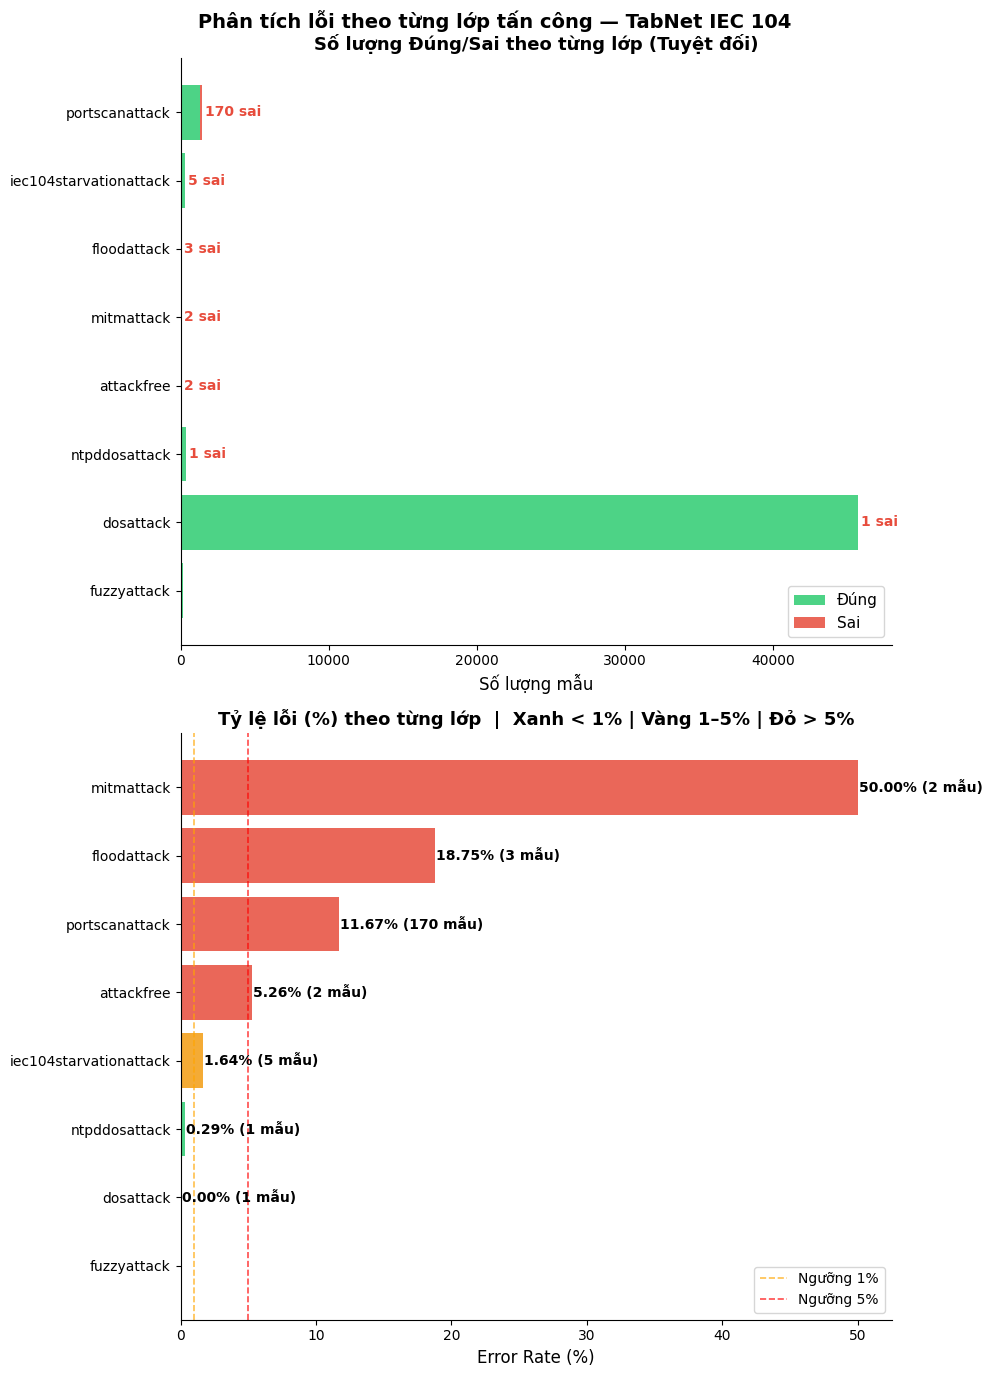

In [29]:
# -----------------------------------------------
# 7.1.3 Biểu đồ phân bố lỗi theo lớp (cải thiện)
# -----------------------------------------------
class_errors = []
for cls_idx, cls_name in enumerate(label_names):
    total_cls   = np.sum(y_test == cls_idx)
    correct_cls = np.sum((y_test == cls_idx) & (y_pred == cls_idx))
    wrong_cls   = total_cls - correct_cls
    class_errors.append({
        'name': cls_name,
        'correct': correct_cls,
        'wrong': wrong_cls,
        'error_pct': wrong_cls / total_cls * 100 if total_cls > 0 else 0
    })

df_err = pd.DataFrame(class_errors).sort_values('wrong', ascending=True)

fig, axes = plt.subplots(2, 1, figsize=(10, 14))  # dọc, 2 hàng thay vì 2 cột

# ── Plot 1: Stacked bar — số lượng tuyệt đối ──
ax1 = axes[0]
bars_c = ax1.barh(df_err['name'], df_err['correct'],
                   color='#2ecc71', label='Đúng', alpha=0.85)
bars_w = ax1.barh(df_err['name'], df_err['wrong'],
                   left=df_err['correct'],
                   color='#e74c3c', label='Sai', alpha=0.85)

for bar, wrong_n, correct_n in zip(bars_w, df_err['wrong'], df_err['correct']):
    if wrong_n > 0:
        ax1.text(
            correct_n + wrong_n + 200,
            bar.get_y() + bar.get_height() / 2,
            f'{int(wrong_n)} sai',
            ha='left', va='center', fontsize=10,
            color='#e74c3c', fontweight='bold'
        )

ax1.set_xlabel('Số lượng mẫu', fontsize=12)
ax1.set_title('Số lượng Đúng/Sai theo từng lớp (Tuyệt đối)',
              fontsize=13, fontweight='bold')
ax1.legend(fontsize=11, loc='lower right')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ── Plot 2: Error % ──
ax2 = axes[1]
df_err_sorted_pct = df_err.sort_values('error_pct', ascending=True)

bar_colors = [
    '#e74c3c' if pct > 5 else
    '#f39c12' if pct > 1 else
    '#2ecc71'
    for pct in df_err_sorted_pct['error_pct']
]

bars_pct = ax2.barh(
    df_err_sorted_pct['name'],
    df_err_sorted_pct['error_pct'],
    color=bar_colors, alpha=0.85
)

for bar, (_, row) in zip(bars_pct, df_err_sorted_pct.iterrows()):
    pct = row['error_pct']
    wrong = int(row['wrong'])
    if pct > 0:
        ax2.text(
            pct + 0.1,
            bar.get_y() + bar.get_height() / 2,
            f'{pct:.2f}% ({wrong} mẫu)',
            ha='left', va='center', fontsize=10, fontweight='bold'
        )

ax2.axvline(x=1, color='orange', linestyle='--',
            alpha=0.7, linewidth=1.2, label='Ngưỡng 1%')
ax2.axvline(x=5, color='red', linestyle='--',
            alpha=0.7, linewidth=1.2, label='Ngưỡng 5%')

ax2.set_xlabel('Error Rate (%)', fontsize=12)
ax2.set_title('Tỷ lệ lỗi (%) theo từng lớp  |  Xanh < 1% | Vàng 1–5% | Đỏ > 5%',
              fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.suptitle('Phân tích lỗi theo từng lớp tấn công — TabNet IEC 104',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(data_dir + 'err_distribution.png', dpi=300, bbox_inches='tight')
print('✓ Đã lưu: err_distribution.png')
plt.show()

Tổng False Positive: 2 mẫu

Bị nhầm thành:
  ntpddosattack                1 mẫu ( 50.0%) █████████████████████████
  fuzzyattack                  1 mẫu ( 50.0%) █████████████████████████

✓ Đã lưu: err_fp_distribution.png


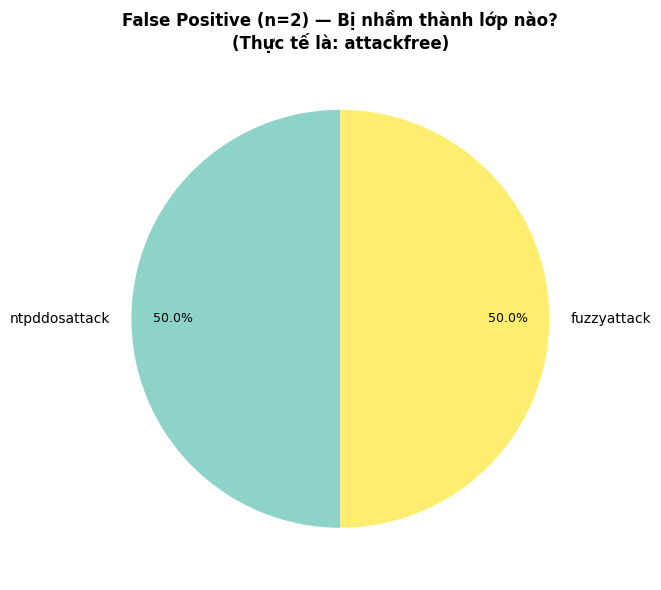

In [30]:
# -----------------------------------------------
# 7.2.1 False Positive bị nhầm thành lớp nào?
# -----------------------------------------------
if len(fp_idx) == 0:
    print('✓ Không có False Positive! Model hoàn hảo với lớp attackfree.')
else:
    fp_predicted_classes = y_pred[fp_idx]
    fp_dist = pd.Series(fp_predicted_classes).map(
        dict(enumerate(label_names))
    ).value_counts()

    print(f'Tổng False Positive: {len(fp_idx)} mẫu')
    print(f'\nBị nhầm thành:')
    for cls_name, cnt in fp_dist.items():
        pct = cnt / len(fp_idx) * 100
        bar = '█' * int(pct / 2)
        print(f'  {cls_name:<25} {cnt:>4} mẫu ({pct:>5.1f}%) {bar}')

    # Biểu đồ pie
    fig, ax = plt.subplots(figsize=(8, 6))
    colors_pie = plt.cm.Set3(np.linspace(0, 1, len(fp_dist)))
    wedges, texts, autotexts = ax.pie(
        fp_dist.values,
        labels=fp_dist.index,
        autopct='%1.1f%%',
        colors=colors_pie,
        startangle=90,
        pctdistance=0.8
    )
    for text in autotexts:
        text.set_fontsize(9)
    ax.set_title(f'False Positive (n={len(fp_idx)}) — Bị nhầm thành lớp nào?\n'
                 f'(Thực tế là: attackfree)',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(data_dir + 'err_fp_distribution.png', dpi=300, bbox_inches='tight')
    print('\n✓ Đã lưu: err_fp_distribution.png')
    plt.show()

✓ Đã lưu: err_fp_feature_compare.png


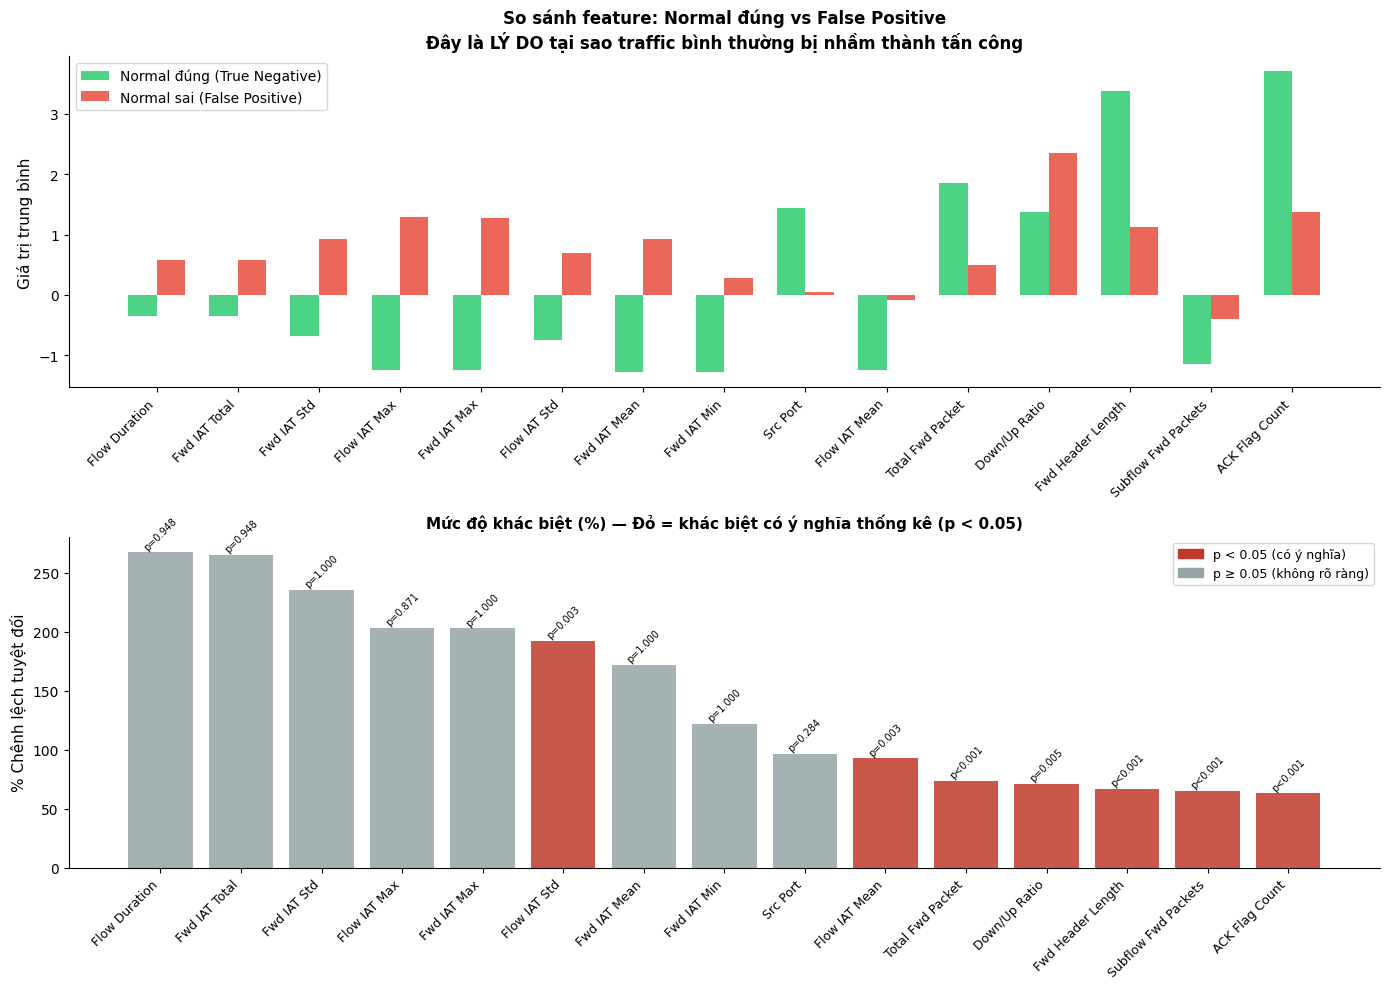


📌 Top 5 features gây ra False Positive:
  1. Flow Duration                  chênh 267.3%    không rõ (p=0.9478)
  2. Fwd IAT Total                  chênh 265.4%    không rõ (p=0.9478)
  3. Fwd IAT Std                    chênh 235.3%    không rõ (p=1.0000)
  4. Flow IAT Max                   chênh 203.5%    không rõ (p=0.8706)
  5. Fwd IAT Max                    chênh 203.0%    không rõ (p=1.0000)


In [31]:
# -----------------------------------------------
# 7.2.2 So sánh feature: Normal đúng vs Normal sai (FP)
#
# Ý tưởng:
# - "Normal đúng" = attackfree được predict đúng
# - "Normal sai" (FP) = attackfree bị predict là attack
# → Hai nhóm này KHÁC NHAU ở feature nào?
# → Đó chính là LÝ DO tại sao FP xảy ra!
# -----------------------------------------------
if len(fp_idx) > 0:
    # Tách 2 nhóm
    normal_correct_mask = (y_test == normal_idx) & (y_pred == normal_idx)
    normal_correct_idx  = np.where(normal_correct_mask)[0]

    X_normal_correct = X_test.values[normal_correct_idx]
    X_fp             = X_test.values[fp_idx]

    # Tính mean của từng feature cho 2 nhóm
    mean_correct = X_normal_correct.mean(axis=0)
    mean_fp      = X_fp.mean(axis=0)

    # Tính % chênh lệch tuyệt đối
    eps  = 1e-8
    diff = np.abs(mean_fp - mean_correct) / (np.abs(mean_correct) + eps)

    # Top 15 features có sự khác biệt lớn nhất
    top_diff_idx = np.argsort(diff)[::-1][:15]

    # Kiểm định Mann-Whitney U (không cần giả định phân phối chuẩn)
    # để xem sự khác biệt có ý nghĩa thống kê không
    pvalues = []
    for fi in top_diff_idx:
        _, pv = mannwhitneyu(
            X_normal_correct[:, fi],
            X_fp[:, fi],
            alternative='two-sided'
        )
        pvalues.append(pv)

    # Vẽ grouped bar chart
    top_feat_names = [feature_names[i][:20] for i in top_diff_idx]
    x = np.arange(len(top_diff_idx))
    w = 0.35

    fig, axes = plt.subplots(2, 1, figsize=(14, 10))

    # --- Plot 1: So sánh mean ---
    ax = axes[0]
    b1 = ax.bar(x - w/2, mean_correct[top_diff_idx], w,
                label='Normal đúng (True Negative)', color='#2ecc71', alpha=0.85)
    b2 = ax.bar(x + w/2, mean_fp[top_diff_idx], w,
                label='Normal sai (False Positive)', color='#e74c3c', alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(top_feat_names, rotation=45, ha='right', fontsize=9)
    ax.set_ylabel('Giá trị trung bình', fontsize=11)
    ax.set_title('So sánh feature: Normal đúng vs False Positive\n'
                 'Đây là LÝ DO tại sao traffic bình thường bị nhầm thành tấn công',
                 fontsize=12, fontweight='bold')
    ax.legend(fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # --- Plot 2: % chênh lệch + p-value ---
    ax2 = axes[1]
    bar_colors = ['#c0392b' if pv < 0.05 else '#95a5a6' for pv in pvalues]
    ax2.bar(x, diff[top_diff_idx] * 100, color=bar_colors, alpha=0.85)
    ax2.set_xticks(x)
    ax2.set_xticklabels(top_feat_names, rotation=45, ha='right', fontsize=9)
    ax2.set_ylabel('% Chênh lệch tuyệt đối', fontsize=11)
    ax2.set_title('Mức độ khác biệt (%) — Đỏ = khác biệt có ý nghĩa thống kê (p < 0.05)',
                  fontsize=11, fontweight='bold')

    # Ghi p-value
    for xi, pv in zip(x, pvalues):
        label_pv = f'p={pv:.3f}' if pv >= 0.001 else 'p<0.001'
        ax2.text(xi, diff[top_diff_idx][list(x).index(xi)] * 100 + 0.5,
                 label_pv, ha='center', va='bottom', fontsize=7, rotation=45)

    red_patch  = mpatches.Patch(color='#c0392b', label='p < 0.05 (có ý nghĩa)')
    gray_patch = mpatches.Patch(color='#95a5a6', label='p ≥ 0.05 (không rõ ràng)')
    ax2.legend(handles=[red_patch, gray_patch], fontsize=9)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)

    plt.tight_layout()
    plt.savefig(data_dir + 'err_fp_feature_compare.png', dpi=300, bbox_inches='tight')
    print('✓ Đã lưu: err_fp_feature_compare.png')
    plt.show()

    # In tóm tắt
    print(f'\n📌 Top 5 features gây ra False Positive:')
    for rank, (fi, pv) in enumerate(zip(top_diff_idx[:5], pvalues[:5]), 1):
        sig = '★ có ý nghĩa' if pv < 0.05 else '  không rõ'
        print(f'  {rank}. {feature_names[fi]:<30} chênh {diff[fi]*100:.1f}%  {sig} (p={pv:.4f})')

Chuẩn bị SHAP Explainer cho False Positive...
Tính SHAP cho 2 mẫu FP...


  0%|          | 0/2 [00:00<?, ?it/s]

✓ SHAP FP xong! shape: (2, 78, 8)
✓ Đã lưu: err_fp_shap_waterfall_1.png


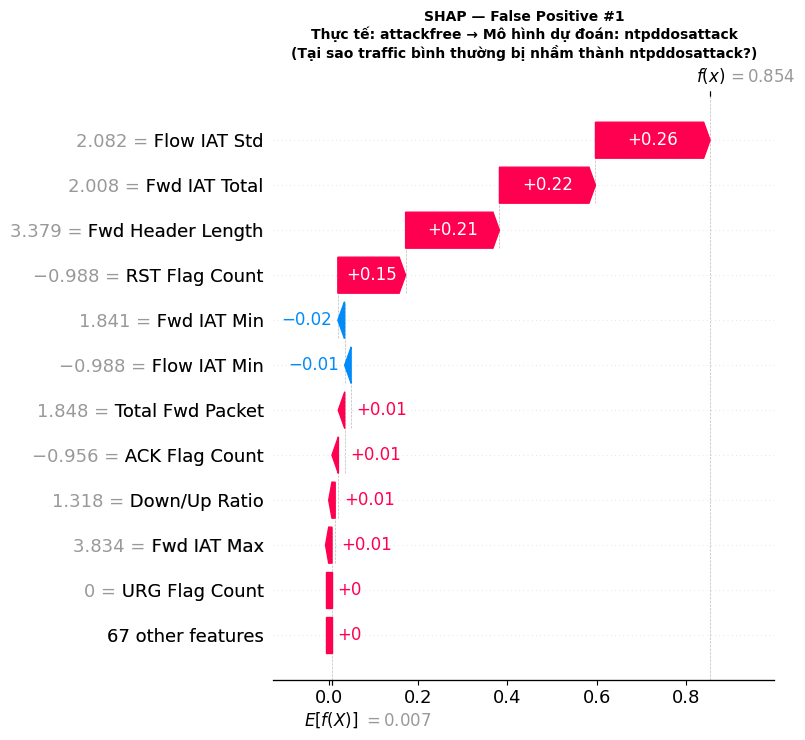

✓ Đã lưu: err_fp_shap_waterfall_2.png


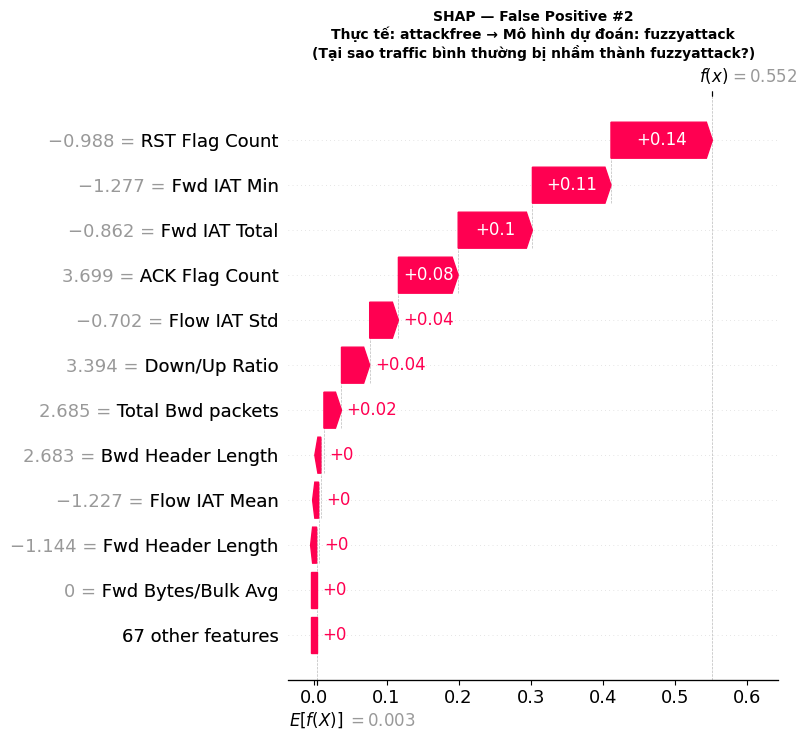


Lớp bị nhầm nhiều nhất: fuzzyattack
✓ Đã lưu: err_fp_shap_summary.png


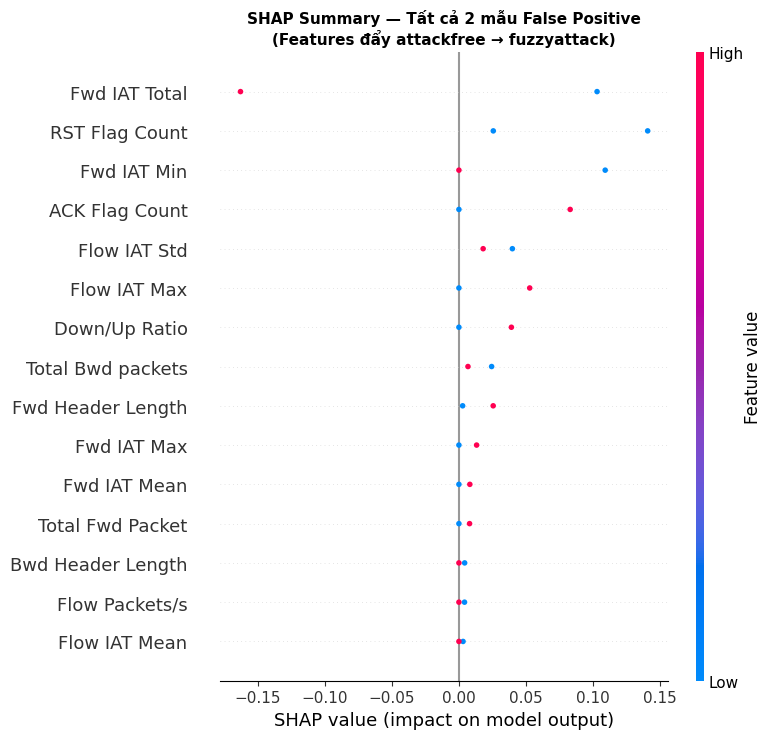

In [32]:
if len(fp_idx) > 0:
    print('Chuẩn bị SHAP Explainer cho False Positive...')

    def predict_fn(x):
        return model.predict_proba(x)

    background = shap.kmeans(X_train.values, 50)
    explainer  = shap.KernelExplainer(predict_fn, background)

    n_fp_shap = min(30, len(fp_idx))
    fp_sample = fp_idx[:n_fp_shap]
    X_fp_shap = X_test.values[fp_sample]
    y_fp_pred = y_pred[fp_sample]

    print(f'Tính SHAP cho {n_fp_shap} mẫu FP...')
    shap_fp_values = explainer.shap_values(X_fp_shap, nsamples='auto')
    print(f'✓ SHAP FP xong! shape: {shap_fp_values.shape}')

    # ── Chuyển đổi shape (n_samples, n_features, n_classes)
    #    → list [class_i → (n_samples, n_features)]
    shap_fp_by_class = [shap_fp_values[:, :, i] for i in range(n_classes)]

    # --- Waterfall cho 3 mẫu FP đầu tiên ---
    n_show = min(3, n_fp_shap)
    for i in range(n_show):
        pred_cls_idx  = int(y_fp_pred[i])
        pred_cls_name = label_names[pred_cls_idx]

        shap_exp = shap.Explanation(
            values        = shap_fp_by_class[pred_cls_idx][i],  # ✅ sửa
            base_values   = explainer.expected_value[pred_cls_idx],
            data          = X_fp_shap[i],
            feature_names = feature_names
        )

        plt.figure(figsize=(10, 6))
        shap.waterfall_plot(shap_exp, max_display=12, show=False)
        plt.title(
            f'SHAP — False Positive #{i+1}\n'
            f'Thực tế: attackfree → Mô hình dự đoán: {pred_cls_name}\n'
            f'(Tại sao traffic bình thường bị nhầm thành {pred_cls_name}?)',
            fontsize=10, fontweight='bold'
        )
        plt.tight_layout()
        plt.savefig(data_dir + f'err_fp_shap_waterfall_{i+1}.png',
                    dpi=300, bbox_inches='tight')
        print(f'✓ Đã lưu: err_fp_shap_waterfall_{i+1}.png')
        plt.show()

    # --- Summary SHAP cho tất cả FP ---
    most_confused_cls = int(pd.Series(y_fp_pred).mode()[0])
    print(f'\nLớp bị nhầm nhiều nhất: {label_names[most_confused_cls]}')

    plt.figure(figsize=(10, 7))
    shap.summary_plot(
        shap_fp_by_class[most_confused_cls],  # ✅ sửa (n_samples, n_features)
        X_fp_shap,
        feature_names=feature_names,
        max_display=15,
        show=False,
        plot_type='dot'
    )
    plt.title(
        f'SHAP Summary — Tất cả {n_fp_shap} mẫu False Positive\n'
        f'(Features đẩy attackfree → {label_names[most_confused_cls]})',
        fontsize=11, fontweight='bold'
    )
    plt.tight_layout()
    plt.savefig(data_dir + 'err_fp_shap_summary.png', dpi=300, bbox_inches='tight')
    print('✓ Đã lưu: err_fp_shap_summary.png')
    plt.show()

Top cặp lỗi phổ biến nhất:
#    True Label                → Predicted                   Số mẫu
----------------------------------------------------------------------
1    portscanattack              dosattack                      163
2    portscanattack              iec104starvationattack           4
3    portscanattack              fuzzyattack                      2
4    iec104starvationattack      dosattack                        2
5    mitmattack                  fuzzyattack                      2
6    floodattack                 attackfree                       2
7    ntpddosattack               iec104starvationattack           1
8    floodattack                 mitmattack                       1
9    iec104starvationattack      floodattack                      1
10   attackfree                  ntpddosattack                    1

✓ Đã lưu: err_mc_top_pairs.png


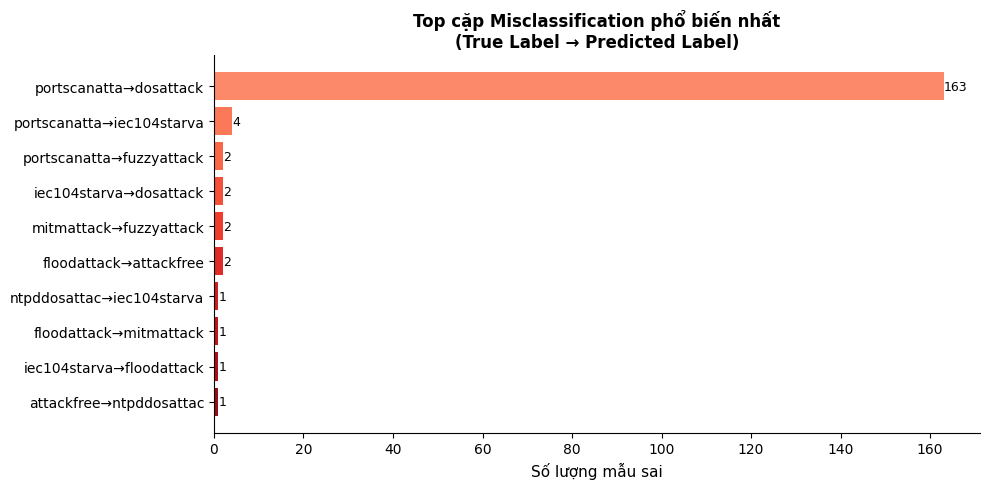

In [33]:
# -----------------------------------------------
# 7.3.1 Top cặp lỗi phổ biến nhất
#
# Từ confusion matrix, tìm các cặp (true, pred)
# có số lỗi cao nhất
# -----------------------------------------------
# Lấy phần ngoài đường chéo của confusion matrix
cm_copy = cm.copy()
np.fill_diagonal(cm_copy, 0)  # Bỏ đường chéo (đúng)

# Top 10 cặp lỗi
n_top_pairs = 10
flat_idx = np.argsort(cm_copy.ravel())[::-1][:n_top_pairs]
error_pairs = [
    (i // n_classes, i % n_classes, cm_copy.ravel()[i])
    for i in flat_idx
    if cm_copy.ravel()[i] > 0
]

print('Top cặp lỗi phổ biến nhất:')
print(f'{"#":<4} {"True Label":<25} → {"Predicted":<25} {"Số mẫu":>8}')
print('-' * 70)
for rank, (true_cls, pred_cls, count) in enumerate(error_pairs, 1):
    print(f'{rank:<4} {label_names[true_cls]:<25}   {label_names[pred_cls]:<25} {count:>8}')

# Biểu đồ bar horizontal
if error_pairs:
    pair_labels = [f'{label_names[t][:12]}→{label_names[p][:12]}'
                   for t, p, _ in error_pairs]
    pair_counts = [c for _, _, c in error_pairs]

    fig, ax = plt.subplots(figsize=(10, 5))
    colors_bar = plt.cm.Reds(np.linspace(0.4, 0.9, len(pair_labels)))[::-1]
    ax.barh(pair_labels[::-1], pair_counts[::-1], color=colors_bar)
    for i, val in enumerate(pair_counts[::-1]):
        ax.text(val + 0.1, i, str(val), va='center', fontsize=9)
    ax.set_xlabel('Số lượng mẫu sai', fontsize=11)
    ax.set_title('Top cặp Misclassification phổ biến nhất\n'
                 '(True Label → Predicted Label)',
                 fontsize=12, fontweight='bold')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.savefig(data_dir + 'err_mc_top_pairs.png', dpi=300, bbox_inches='tight')
    print('\n✓ Đã lưu: err_mc_top_pairs.png')
    plt.show()

Phân tích cặp lỗi #1: portscanattack → dosattack (163 mẫu)
Features có variance: 22/78
✓ Đã lưu: err_mc_feature_overlap.png


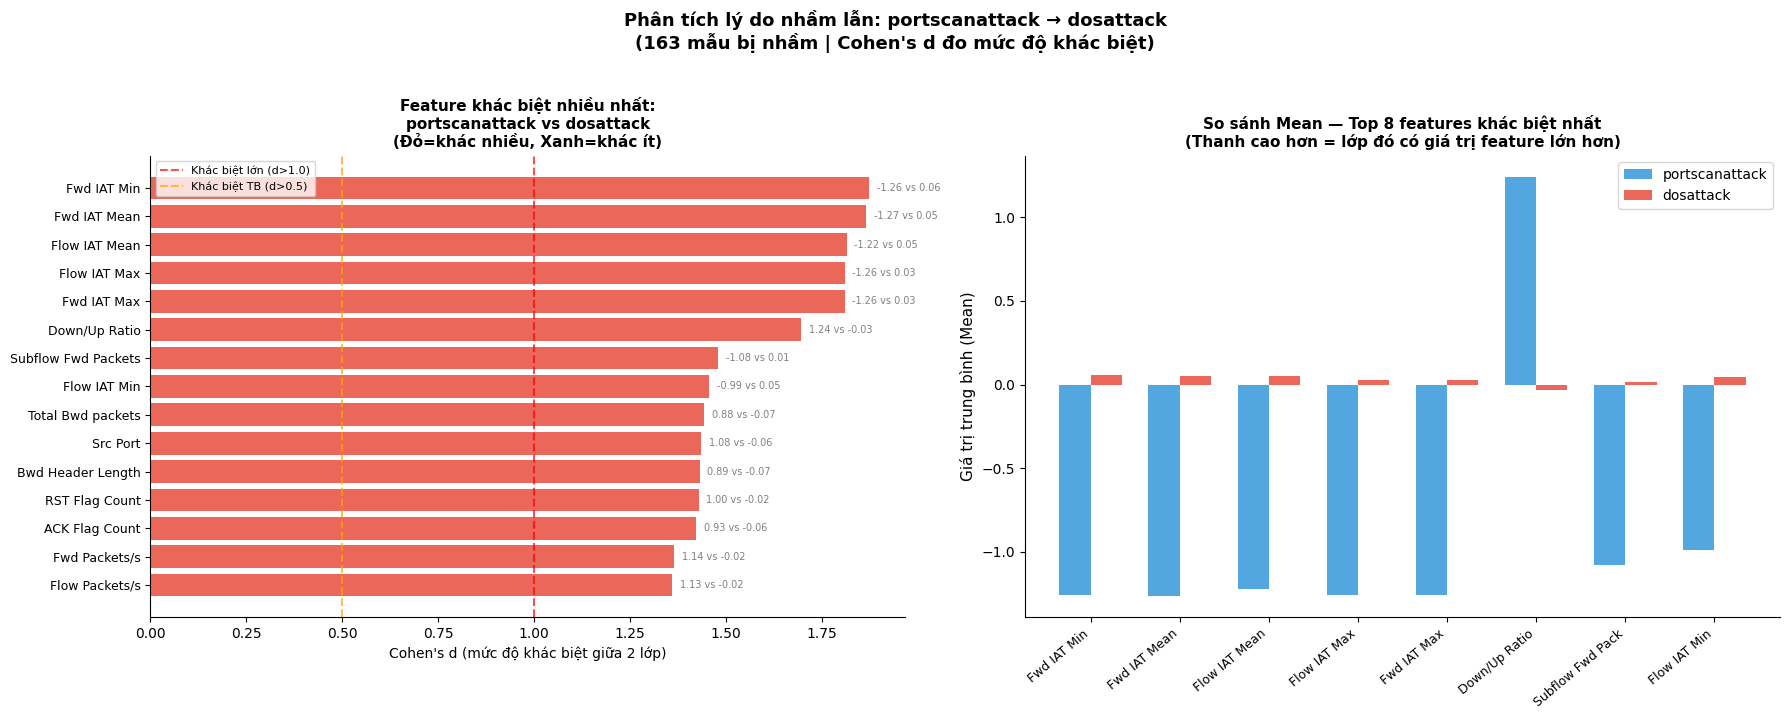


📌 Tóm tắt phân tích:
  Features có variance:         22
  Features khác biệt lớn (d>1): 20
  Features khác biệt nhỏ (d<0.5): 0/22

→ KẾT LUẬN:
  portscanattack và dosattack có features KHÁC NHAU rõ ràng
  → Lỗi có thể do model chưa học được pattern này


In [34]:
if error_pairs:
    true_cls_idx, pred_cls_idx, n_errors = error_pairs[0]
    true_cls_name = label_names[true_cls_idx]
    pred_cls_name = label_names[pred_cls_idx]

    print(f'Phân tích cặp lỗi #1: {true_cls_name} → {pred_cls_name} ({n_errors} mẫu)')

    X_true_cls = X_test.values[y_test == true_cls_idx]
    X_pred_cls = X_test.values[y_test == pred_cls_idx]

    mean_true = X_true_cls.mean(axis=0)
    mean_pred = X_pred_cls.mean(axis=0)
    std_true  = X_true_cls.std(axis=0)
    std_pred  = X_pred_cls.std(axis=0)

    # ── Lọc features có variance > 0 ở ÍT NHẤT 1 lớp ──
    # Tránh chọn features toàn bộ = 0 (vô nghĩa)
    has_variance = (std_true > 1e-6) | (std_pred > 1e-6)
    valid_idx    = np.where(has_variance)[0]
    print(f'Features có variance: {len(valid_idx)}/{len(feature_names)}')

    # ── Tính mean difference thay vì Bhattacharyya ──
    # Với dữ liệu có nhiều zero → dùng mean difference rõ ràng hơn
    mean_diff = np.abs(mean_true - mean_pred)

    # Chuẩn hóa theo std trung bình (Cohen's d)
    pooled_std = np.sqrt((std_true**2 + std_pred**2) / 2 + 1e-8)
    cohens_d   = mean_diff / pooled_std

    # Chỉ xét trong valid features
    cohens_d_valid = cohens_d.copy()
    cohens_d_valid[~has_variance] = 0

    # Top 15 features có Cohen's d lớn nhất (khác nhau nhất)
    top_diff_idx = np.argsort(cohens_d_valid)[::-1][:15]

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))

    # ── Plot 1: Cohen's d — mức độ khác biệt ──
    ax = axes[0]
    top_d      = cohens_d_valid[top_diff_idx][::-1]
    top_labels = [feature_names[i][:22] for i in top_diff_idx[::-1]]
    bar_colors = [
        '#e74c3c' if d > 1.0 else   # Khác biệt lớn
        '#f39c12' if d > 0.5 else   # Khác biệt trung bình
        '#2ecc71'                    # Khác biệt nhỏ
        for d in top_d
    ]
    bars = ax.barh(range(15), top_d, color=bar_colors, alpha=0.85)
    ax.set_yticks(range(15))
    ax.set_yticklabels(top_labels, fontsize=9)
    ax.axvline(x=1.0, color='red',    linestyle='--', alpha=0.7, label="Khác biệt lớn (d>1.0)")
    ax.axvline(x=0.5, color='orange', linestyle='--', alpha=0.7, label="Khác biệt TB (d>0.5)")

    # Ghi giá trị mean của 2 lớp lên thanh
    for i, (bar, fi) in enumerate(zip(bars[::-1], top_diff_idx)):
        ax.text(
            bar.get_width() + 0.02,
            bar.get_y() + bar.get_height()/2,
            f'{mean_true[fi]:.2f} vs {mean_pred[fi]:.2f}',
            va='center', fontsize=7, color='gray'
        )

    ax.set_xlabel("Cohen's d (mức độ khác biệt giữa 2 lớp)", fontsize=10)
    ax.set_title(f'Feature khác biệt nhiều nhất:\n{true_cls_name} vs {pred_cls_name}\n'
                 f'(Đỏ=khác nhiều, Xanh=khác ít)',
                 fontsize=11, fontweight='bold')
    ax.legend(fontsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # ── Plot 2: Bar so sánh mean của top 8 features ──
    # Dễ hiểu hơn violin khi data có nhiều zero
    ax2 = axes[1]
    top8_idx = top_diff_idx[:8]
    x        = np.arange(len(top8_idx))
    w        = 0.35

    b1 = ax2.bar(x - w/2,
                  mean_true[top8_idx],
                  w, label=true_cls_name,
                  color='#3498db', alpha=0.85)
    b2 = ax2.bar(x + w/2,
                  mean_pred[top8_idx],
                  w, label=pred_cls_name,
                  color='#e74c3c', alpha=0.85)

    ax2.set_xticks(x)
    ax2.set_xticklabels(
        [feature_names[i][:16] for i in top8_idx],
        rotation=40, ha='right', fontsize=9
    )
    ax2.set_ylabel('Giá trị trung bình (Mean)', fontsize=11)
    ax2.set_title(f'So sánh Mean — Top 8 features khác biệt nhất\n'
                  f'(Thanh cao hơn = lớp đó có giá trị feature lớn hơn)',
                  fontsize=11, fontweight='bold')
    ax2.legend(fontsize=10)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)

    plt.suptitle(
        f'Phân tích lý do nhầm lẫn: {true_cls_name} → {pred_cls_name}\n'
        f'({n_errors} mẫu bị nhầm | Cohen\'s d đo mức độ khác biệt)',
        fontsize=13, fontweight='bold', y=1.02
    )
    plt.tight_layout()
    plt.savefig(data_dir + 'err_mc_feature_overlap.png', dpi=300, bbox_inches='tight')
    print('✓ Đã lưu: err_mc_feature_overlap.png')
    plt.show()

    # ── Kết luận tự động ──
    large_diff = np.sum(cohens_d_valid > 1.0)
    small_diff = np.sum(cohens_d_valid[valid_idx] < 0.5)
    total_valid = len(valid_idx)

    print(f'\n📌 Tóm tắt phân tích:')
    print(f'  Features có variance:         {total_valid}')
    print(f'  Features khác biệt lớn (d>1): {large_diff}')
    print(f'  Features khác biệt nhỏ (d<0.5): {small_diff}/{total_valid}')
    print(f'\n→ KẾT LUẬN:')
    if small_diff / (total_valid + 1e-8) > 0.5:
        print(f'  {true_cls_name} và {pred_cls_name} có nhiều features GIỐNG NHAU')
        print(f'  → Lỗi do DATA AMBIGUITY, không phải model kém!')
    else:
        print(f'  {true_cls_name} và {pred_cls_name} có features KHÁC NHAU rõ ràng')
        print(f'  → Lỗi có thể do model chưa học được pattern này')

Tính SHAP cho 20 mẫu so sánh...


  0%|          | 0/20 [00:00<?, ?it/s]

✓ Đã lưu: err_mc_shap_compare.png


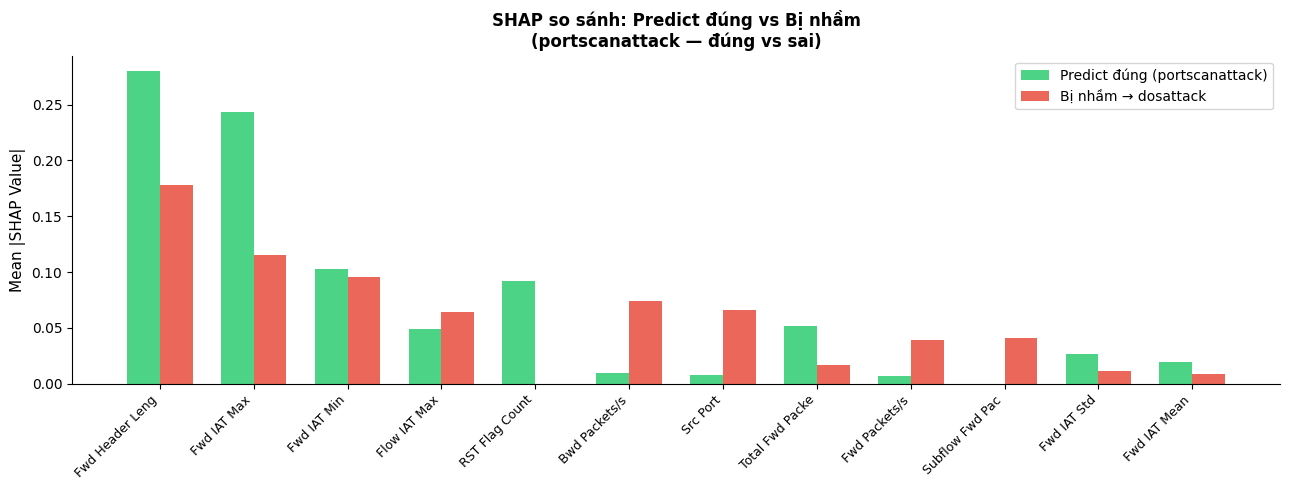

✓ Đã lưu: err_mc_shap_waterfall.png


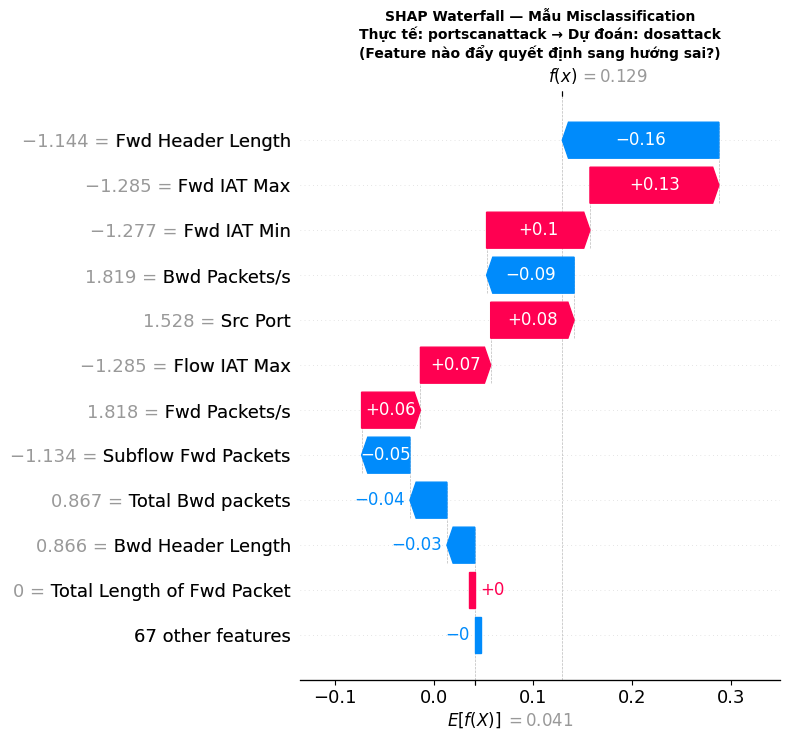

In [35]:
if error_pairs and len(mc_idx) > 0:
    true_cls_idx, pred_cls_idx, _ = error_pairs[0]

    tp_mask      = (y_test == true_cls_idx) & (y_pred == true_cls_idx)
    tp_idx_arr   = np.where(tp_mask)[0][:10]
    mc_pair_mask = (y_test == true_cls_idx) & (y_pred == pred_cls_idx)
    mc_pair_idx  = np.where(mc_pair_mask)[0][:10]

    if len(tp_idx_arr) > 0 and len(mc_pair_idx) > 0:
        X_compare = np.vstack([
            X_test.values[tp_idx_arr],
            X_test.values[mc_pair_idx]
        ])

        print(f'Tính SHAP cho {len(X_compare)} mẫu so sánh...')
        shap_compare = explainer.shap_values(X_compare, nsamples='auto')
        # shap_compare.shape = (n_samples, n_features, n_classes)

        # ✅ Sửa: lấy đúng class theo axis=2
        n_tp    = len(tp_idx_arr)
        shap_tp = shap_compare[:n_tp, :, true_cls_idx]   # (n_tp, n_features)
        shap_mc = shap_compare[n_tp:, :, true_cls_idx]   # (n_mc, n_features)

        mean_shap_tp = np.abs(shap_tp).mean(axis=0)
        mean_shap_mc = np.abs(shap_mc).mean(axis=0)

        top_shap_idx = np.argsort(mean_shap_tp + mean_shap_mc)[::-1][:12]
        x = np.arange(len(top_shap_idx))
        w = 0.35

        fig, ax = plt.subplots(figsize=(13, 5))
        ax.bar(x - w/2, mean_shap_tp[top_shap_idx], w,
               label=f'Predict đúng ({label_names[true_cls_idx]})',
               color='#2ecc71', alpha=0.85)
        ax.bar(x + w/2, mean_shap_mc[top_shap_idx], w,
               label=f'Bị nhầm → {label_names[pred_cls_idx]}',
               color='#e74c3c', alpha=0.85)
        ax.set_xticks(x)
        ax.set_xticklabels(
            [feature_names[i][:15] for i in top_shap_idx],
            rotation=45, ha='right', fontsize=9
        )
        ax.set_ylabel('Mean |SHAP Value|', fontsize=11)
        ax.set_title(
            f'SHAP so sánh: Predict đúng vs Bị nhầm\n'
            f'({label_names[true_cls_idx]} — đúng vs sai)',
            fontsize=12, fontweight='bold'
        )
        ax.legend(fontsize=10)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        plt.tight_layout()
        plt.savefig(data_dir + 'err_mc_shap_compare.png', dpi=300, bbox_inches='tight')
        print('✓ Đã lưu: err_mc_shap_compare.png')
        plt.show()

        # ✅ Sửa: waterfall dùng shap_mc[0] đã đúng shape (n_features,)
        shap_exp_mc = shap.Explanation(
            values        = shap_mc[0],                              # (n_features,) ✓
            base_values   = explainer.expected_value[true_cls_idx],
            data          = X_test.values[mc_pair_idx[0]],
            feature_names = feature_names
        )
        plt.figure(figsize=(10, 6))
        shap.waterfall_plot(shap_exp_mc, max_display=12, show=False)
        plt.title(
            f'SHAP Waterfall — Mẫu Misclassification\n'
            f'Thực tế: {label_names[true_cls_idx]} → Dự đoán: {label_names[pred_cls_idx]}\n'
            f'(Feature nào đẩy quyết định sang hướng sai?)',
            fontsize=10, fontweight='bold'
        )
        plt.tight_layout()
        plt.savefig(data_dir + 'err_mc_shap_waterfall.png', dpi=300, bbox_inches='tight')
        print('✓ Đã lưu: err_mc_shap_waterfall.png')
        plt.show()

✓ Đã lưu: err_confidence_analysis.png


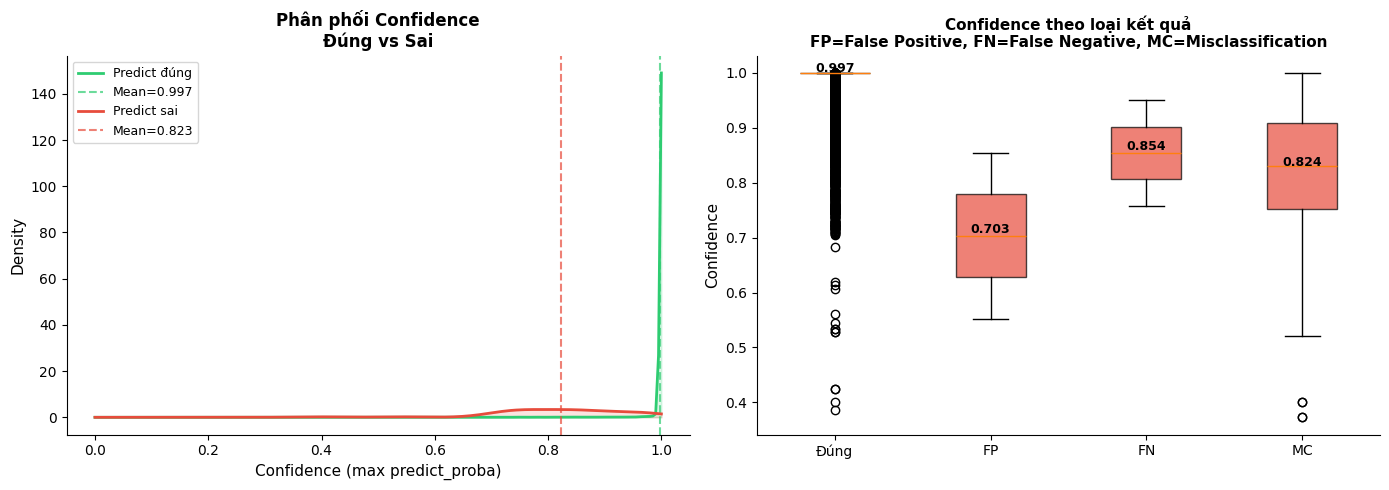


📌 Tóm tắt Confidence:
  Predict đúng: mean = 0.9969
  Predict sai:  mean = 0.8232
  → Khoảng cách = 0.1738: Model có xu hướng ít tự tin hơn khi sai ✓
  → Đề xuất: Đặt ngưỡng cảnh báo tại confidence < 0.82


In [36]:
# -----------------------------------------------
# 7.4 Confidence của dự đoán đúng vs sai
#
# Confidence = max(predict_proba) của mỗi mẫu
# → Mẫu đúng thường có confidence cao
# → Mẫu sai thường có confidence thấp hơn
#    (nếu không → model overconfident)
# -----------------------------------------------
confidence = y_pred_proba.max(axis=1)  # Confidence = xác suất lớp được chọn

correct_mask = (y_pred == y_test)
conf_correct = confidence[correct_mask]
conf_wrong   = confidence[~correct_mask]

# Phân theo loại lỗi
conf_fp = confidence[fp_mask]  if len(fp_idx) > 0 else np.array([])
conf_fn = confidence[fn_mask]  if len(fn_idx) > 0 else np.array([])
conf_mc = confidence[mc_mask]  if len(mc_idx) > 0 else np.array([])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: KDE distribution ---
ax = axes[0]
from scipy.stats import gaussian_kde
for data, label, color in [
    (conf_correct, 'Predict đúng', '#2ecc71'),
    (conf_wrong,   'Predict sai',  '#e74c3c'),
]:
    if len(data) > 1:
        kde  = gaussian_kde(data)
        x_kd = np.linspace(0, 1, 200)
        ax.plot(x_kd, kde(x_kd), label=label, color=color, linewidth=2)
        ax.fill_between(x_kd, kde(x_kd), alpha=0.15, color=color)
        ax.axvline(data.mean(), color=color, linestyle='--',
                   alpha=0.7, label=f'Mean={data.mean():.3f}')

ax.set_xlabel('Confidence (max predict_proba)', fontsize=11)
ax.set_ylabel('Density', fontsize=11)
ax.set_title('Phân phối Confidence\nĐúng vs Sai', fontsize=12, fontweight='bold')
ax.legend(fontsize=9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# --- Plot 2: Confidence theo loại lỗi ---
ax2 = axes[1]
data_box   = [conf_correct]
labels_box = ['Đúng']
if len(conf_fp) > 0: data_box.append(conf_fp); labels_box.append('FP')
if len(conf_fn) > 0: data_box.append(conf_fn); labels_box.append('FN')
if len(conf_mc) > 0: data_box.append(conf_mc); labels_box.append('MC')

bp = ax2.boxplot(data_box, labels=labels_box, patch_artist=True)
box_colors = ['#2ecc71', '#e74c3c', '#e74c3c', '#e74c3c']
for patch, color in zip(bp['boxes'], box_colors[:len(data_box)]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# Ghi mean
for i, data in enumerate(data_box, 1):
    ax2.text(i, data.mean(), f'{data.mean():.3f}',
             ha='center', va='bottom', fontsize=9, fontweight='bold')

ax2.set_ylabel('Confidence', fontsize=11)
ax2.set_title('Confidence theo loại kết quả\n'
              'FP=False Positive, FN=False Negative, MC=Misclassification',
              fontsize=11, fontweight='bold')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(data_dir + 'err_confidence_analysis.png', dpi=300, bbox_inches='tight')
print('✓ Đã lưu: err_confidence_analysis.png')
plt.show()

print(f'\n📌 Tóm tắt Confidence:')
print(f'  Predict đúng: mean = {conf_correct.mean():.4f}')
if len(conf_wrong) > 0:
    print(f'  Predict sai:  mean = {conf_wrong.mean():.4f}')
    gap = conf_correct.mean() - conf_wrong.mean()
    if gap > 0.1:
        print(f'  → Khoảng cách = {gap:.4f}: Model có xu hướng ít tự tin hơn khi sai ✓')
        print(f'  → Đề xuất: Đặt ngưỡng cảnh báo tại confidence < {conf_wrong.mean():.2f}')
    else:
        print(f'  → Khoảng cách = {gap:.4f}: Model tự tin ngay cả khi sai → cần cẩn thận')

✓ Đã lưu: err_trust_assessment.png


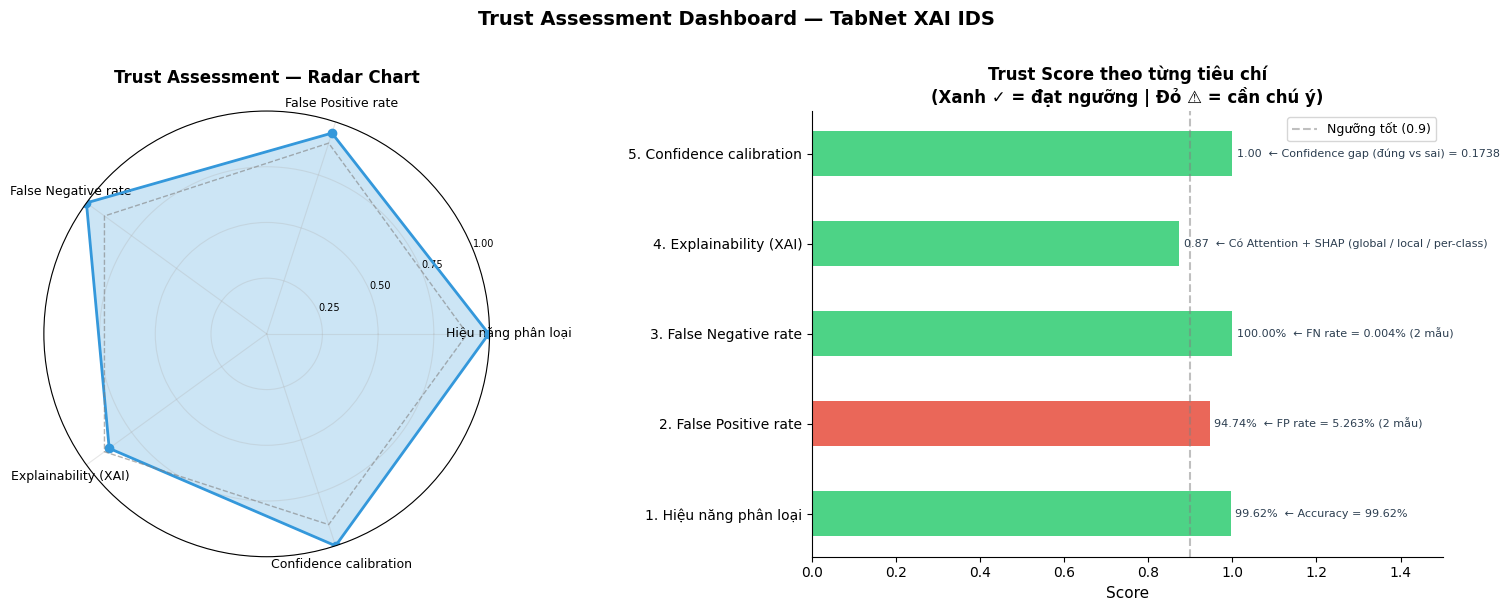


              KẾT LUẬN — XAI ERROR ANALYSIS
  ✓ TỐT    1. Hiệu năng phân loại
           Accuracy = 99.62%
  ⚠ CHÚ Ý  2. False Positive rate
           FP rate = 5.263% (2 mẫu)
  ✓ TỐT    3. False Negative rate
           FN rate = 0.004% (2 mẫu)
  ✓ TỐT    4. Explainability (XAI)
           Có Attention + SHAP (global / local / per-class)
  ✓ TỐT    5. Confidence calibration
           Confidence gap (đúng vs sai) = 0.1738


In [37]:
# -----------------------------------------------
# 7.5 Trust Assessment Dashboard
# -----------------------------------------------
from sklearn.metrics import classification_report

total    = len(y_test)
n_normal = np.sum(y_test == normal_idx)
n_attack = total - n_normal

fp_rate = len(fp_idx) / n_normal if n_normal > 0 else 0
fn_rate = len(fn_idx) / n_attack if n_attack > 0 else 0
acc     = (y_pred == y_test).mean()

# ✅ Sửa: feat_imp đã tính từ Phần 2.1 (explain_matrix.mean(axis=0))
# Không dùng model.feature_importances_ nữa
# feat_imp đã có sẵn trong memory — không cần khai báo lại

# Confidence gap
conf_gap = conf_correct.mean() - conf_wrong.mean() if len(conf_wrong) > 0 else 0

# 5 tiêu chí
criteria = [
    {
        'name':  '1. Hiệu năng phân loại',
        'value': acc,
        'threshold_good': 0.95,
        'format': '{:.2%}',
        'note':  f'Accuracy = {acc*100:.2f}%'
    },
    {
        'name':  '2. False Positive rate',
        'value': 1 - fp_rate,
        'threshold_good': 0.95,
        'format': '{:.2%}',
        'note':  f'FP rate = {fp_rate*100:.3f}% ({len(fp_idx)} mẫu)'
    },
    {
        'name':  '3. False Negative rate',
        'value': 1 - fn_rate,
        'threshold_good': 0.95,
        'format': '{:.2%}',
        'note':  f'FN rate = {fn_rate*100:.3f}% ({len(fn_idx)} mẫu)'
    },
    {
        'name':  '4. Explainability (XAI)',
        'value': min(1.0, 0.7 + conf_gap),
        'threshold_good': 0.80,
        'format': '{:.2f}',
        'note':  'Có Attention + SHAP (global / local / per-class)'
    },
    {
        'name':  '5. Confidence calibration',
        'value': min(1.0, 0.5 + conf_gap * 3),
        'threshold_good': 0.70,
        'format': '{:.2f}',
        'note':  f'Confidence gap (đúng vs sai) = {conf_gap:.4f}'
    },
]

# ── Radar chart + Bar chart ──
labels_radar = [c['name'].split('.')[1].strip() for c in criteria]
values_radar = [c['value'] for c in criteria]
values_radar_closed = values_radar + values_radar[:1]  # Đóng vòng

angles = np.linspace(0, 2*np.pi, len(labels_radar), endpoint=False).tolist()
angles_closed = angles + angles[:1]

# ✅ Sửa: tạo figure đúng cách — không mix subplot_kw với add_subplot
fig = plt.figure(figsize=(16, 6))

# --- Radar ---
ax_radar = fig.add_subplot(121, polar=True)
ax_radar.plot(angles_closed, values_radar_closed,
              'o-', linewidth=2, color='#3498db')
ax_radar.fill(angles_closed, values_radar_closed,
              alpha=0.25, color='#3498db')

# Vẽ đường ngưỡng tham chiếu
threshold_vals = [0.9] * len(labels_radar) + [0.9]
ax_radar.plot(angles_closed, threshold_vals,
              '--', linewidth=1, color='gray', alpha=0.6, label='Ngưỡng 0.9')

ax_radar.set_xticks(angles)
ax_radar.set_xticklabels(labels_radar, fontsize=9)
ax_radar.set_ylim(0, 1)
ax_radar.set_yticks([0.25, 0.5, 0.75, 1.0])
ax_radar.set_yticklabels(['0.25', '0.50', '0.75', '1.00'], fontsize=7)
ax_radar.set_title('Trust Assessment — Radar Chart',
                    fontsize=12, fontweight='bold', pad=20)
ax_radar.grid(True, alpha=0.3)

# --- Bar chart ---
ax_bar = fig.add_subplot(122)
bar_colors = [
    '#2ecc71' if c['value'] >= c['threshold_good'] else '#e74c3c'
    for c in criteria
]
bars = ax_bar.barh(
    [c['name'] for c in criteria],
    [c['value'] for c in criteria],
    color=bar_colors, alpha=0.85, height=0.5
)
ax_bar.axvline(x=0.9, color='gray', linestyle='--',
               alpha=0.5, label='Ngưỡng tốt (0.9)')

# Ghi giá trị + note lên từng thanh
for bar, c in zip(bars, criteria):
    val_str = c['format'].format(c['value'])
    ax_bar.text(
        bar.get_width() + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f'{val_str}  ← {c["note"]}',
        va='center', fontsize=8,
        color='#2c3e50'
    )

ax_bar.set_xlim(0, 1.5)  # Mở rộng để note không bị cắt
ax_bar.set_xlabel('Score', fontsize=11)
ax_bar.set_title('Trust Score theo từng tiêu chí\n'
                  '(Xanh ✓ = đạt ngưỡng | Đỏ ⚠ = cần chú ý)',
                  fontsize=12, fontweight='bold')
ax_bar.legend(fontsize=9)
ax_bar.spines['top'].set_visible(False)
ax_bar.spines['right'].set_visible(False)

plt.suptitle('Trust Assessment Dashboard — TabNet XAI IDS',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(data_dir + 'err_trust_assessment.png', dpi=300, bbox_inches='tight')
print('✓ Đã lưu: err_trust_assessment.png')
plt.show()

# ── In kết luận cuối ──
print('\n' + '=' * 70)
print('              KẾT LUẬN — XAI ERROR ANALYSIS')
print('=' * 70)
for c in criteria:
    status = '✓ TỐT  ' if c['value'] >= c['threshold_good'] else '⚠ CHÚ Ý'
    print(f'  {status}  {c["name"]}')
    print(f'           {c["note"]}')


In [38]:
# Tổng kết tất cả file đã lưu trong Phần 7
print('=' * 65)
print('    TẤT CẢ FILE ĐÃ LƯU — PHẦN 7: XAI ERROR ANALYSIS')
print('=' * 65)
files_p7 = [
    ('err_confusion_matrix.png',    '7.1 — Confusion matrix (raw + normalized)'),
    ('err_distribution.png',        '7.1 — Phân bố Đúng/Sai theo từng lớp'),
    ('err_fp_distribution.png',     '7.2 — FP bị nhầm thành lớp nào'),
    ('err_fp_feature_compare.png',  '7.2 — Feature khác biệt giữa Normal đúng vs FP'),
    ('err_fp_shap_waterfall_*.png', '7.2 — SHAP waterfall cho từng mẫu FP'),
    ('err_fp_shap_summary.png',     '7.2 — SHAP summary cho tất cả FP'),
    ('err_mc_top_pairs.png',        '7.3 — Top cặp Misclassification'),
    ('err_mc_feature_overlap.png',  '7.3 — Feature overlap giữa 2 lớp bị nhầm'),
    ('err_mc_shap_compare.png',     '7.3 — SHAP so sánh đúng vs sai'),
    ('err_mc_shap_waterfall.png',   '7.3 — SHAP waterfall cho mẫu bị nhầm'),
    ('err_confidence_analysis.png', '7.4 — Confidence đúng vs sai'),
    ('err_trust_assessment.png',    '7.5 — Trust Assessment dashboard'),
]
for fname, desc in files_p7:
    print(f'  {fname:<38} ← {desc}')
print('=' * 65)

    TẤT CẢ FILE ĐÃ LƯU — PHẦN 7: XAI ERROR ANALYSIS
  err_confusion_matrix.png               ← 7.1 — Confusion matrix (raw + normalized)
  err_distribution.png                   ← 7.1 — Phân bố Đúng/Sai theo từng lớp
  err_fp_distribution.png                ← 7.2 — FP bị nhầm thành lớp nào
  err_fp_feature_compare.png             ← 7.2 — Feature khác biệt giữa Normal đúng vs FP
  err_fp_shap_waterfall_*.png            ← 7.2 — SHAP waterfall cho từng mẫu FP
  err_fp_shap_summary.png                ← 7.2 — SHAP summary cho tất cả FP
  err_mc_top_pairs.png                   ← 7.3 — Top cặp Misclassification
  err_mc_feature_overlap.png             ← 7.3 — Feature overlap giữa 2 lớp bị nhầm
  err_mc_shap_compare.png                ← 7.3 — SHAP so sánh đúng vs sai
  err_mc_shap_waterfall.png              ← 7.3 — SHAP waterfall cho mẫu bị nhầm
  err_confidence_analysis.png            ← 7.4 — Confidence đúng vs sai
  err_trust_assessment.png               ← 7.5 — Trust Assessment dashboard


In [39]:
import json

# ✅ Tính lại metrics để tránh bị ghi đè bởi biến khác
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score
from sklearn.preprocessing import label_binarize

acc_final                    = accuracy_score(y_test, y_pred)
prec_final, rec_final, f1_final, _ = precision_recall_fscore_support(
    y_test, y_pred, average='macro'
)
y_test_bin = label_binarize(y_test, classes=range(n_classes))
auc_final  = roc_auc_score(y_test_bin, y_pred_proba, multi_class='ovr', average='macro')

final_results = {
    'tabnet_performance': {
        'accuracy':        round(float(acc_final),   4),
        'macro_precision': round(float(prec_final),  4),
        'macro_recall':    round(float(rec_final),   4),
        'macro_f1':        round(float(f1_final),    4),
        'macro_auc':       round(float(auc_final),   4),
    },
    'xai_intrinsic_attention': {
        'top10_features': top10_attention,
        'scores': {
            feature_names[i]: round(float(feat_imp[i]), 6)
            for i in sorted_idx[:10]
        }
    },
    'xai_posthoc_shap': {
        'top10_features': top10_shap,
        'scores': {
            feature_names[i]: round(float(mean_shap_global[i]), 6)
            for i in shap_sorted_idx[:10]
        }
    },
    'xai_comparison': {
        'overlap_at_10':        int(overlap_n),
        'overlap_features':     list(overlap_set),
        'spearman_correlation': round(float(corr), 4),
        'spearman_pvalue':      round(float(pval), 6),
    },
    'error_analysis': {
        'total_errors':          int(is_wrong.sum()),
        'false_positive':        int(len(fp_idx)),
        'false_negative':        int(len(fn_idx)),
        'misclassification':     int(len(mc_idx)),
        'fp_rate':               round(float(len(fp_idx) / np.sum(y_test == normal_idx)), 6),
        'fn_rate':               round(float(len(fn_idx) / np.sum(y_test != normal_idx)), 6),
        'confidence_correct':    round(float(conf_correct.mean()), 4),
        'confidence_wrong':      round(float(conf_wrong.mean()), 4) if len(conf_wrong) > 0 else None,
        'confidence_gap':        round(float(conf_gap), 4),
    },
    'dataset': {
        'name':       'IEC 104 - Electrical Substations IDS',
        'n_classes':  int(n_classes),
        'classes':    list(label_names),
        'n_features': int(len(feature_names)),
        'n_train':    int(X_train.shape[0]),
        'n_val':      int(X_val.shape[0]),
        'n_test':     int(X_test.shape[0]),
    }
}

with open(data_dir + 'luanvan_xai_results.json', 'w', encoding='utf-8') as f:
    json.dump(final_results, f, indent=4, ensure_ascii=False)

# ── In tổng kết ──
print('=' * 65)
print('      TỔNG KẾT LUẬN VĂN — TabNet + XAI + Error Analysis')
print('=' * 65)

print(f'\n📌 MÔ HÌNH: TabNet')
print(f'  Accuracy:        {acc_final*100:.2f}%')
print(f'  Macro Precision: {prec_final:.4f}')
print(f'  Macro Recall:    {rec_final:.4f}')
print(f'  Macro F1:        {f1_final:.4f}')
print(f'  Macro AUC:       {auc_final:.4f}')

print(f'\n📌 XAI TẦNG 1 — TabNet Attention (Intrinsic):')
print(f'  Top 5: {top10_attention[:5]}')

print(f'\n📌 XAI TẦNG 2 — SHAP (Post-hoc):')
print(f'  Top 5: {top10_shap[:5]}')

print(f'\n📌 SO SÁNH 2 TẦNG XAI:')
print(f'  Overlap@10:          {overlap_n}/10 ({overlap_n*10}%)')
print(f'  Spearman r:          {corr:.4f}')
print(f'  Features đồng thuận: {list(overlap_set)}')

print(f'\n📌 ERROR ANALYSIS:')
print(f'  Tổng lỗi:          {int(is_wrong.sum())} / {len(y_test)} mẫu ({is_wrong.mean()*100:.2f}%)')
print(f'  False Positive:    {len(fp_idx)} mẫu (FP rate = {len(fp_idx)/np.sum(y_test==normal_idx)*100:.3f}%)')
print(f'  False Negative:    {len(fn_idx)} mẫu')
print(f'  Misclassification: {len(mc_idx)} mẫu')
print(f'  Confidence gap:    {conf_gap:.4f} (đúng={conf_correct.mean():.4f} | sai={conf_wrong.mean():.4f})')

print(f'\n📌 CÁC FILE ĐÃ LƯU:')
files_saved = [
    ('att_global.png',              'Attention Global top 20'),
    ('att_per_step.png',            'Attention per Decision Step'),
    ('att_per_class.png',           'Attention per Attack Class'),
    ('shap_global_beeswarm.png',    'SHAP Summary beeswarm'),
    ('shap_global_bar.png',         'SHAP Bar Global'),
    ('shap_per_class_heatmap.png',  'SHAP Heatmap per class'),
    ('shap_per_class_subplots.png', 'SHAP Bar per class (8 subplots)'),
    ('shap_waterfall_*.png',        'SHAP Waterfall Local'),
    ('xai_attention_vs_shap.png',   'So sánh Attention vs SHAP'),
    ('xai_correlation_scatter.png', 'Scatter tương quan 2 tầng XAI'),
    ('err_confusion_matrix.png',    'Confusion Matrix'),
    ('err_distribution.png',        'Phân bố lỗi theo lớp'),
    ('err_fp_feature_compare.png',  'Feature Normal đúng vs FP'),
    ('err_fp_shap_summary.png',     'SHAP tất cả FP'),
    ('err_mc_feature_overlap.png',  'Feature overlap cặp nhầm lẫn'),
    ('err_confidence_analysis.png', 'Confidence đúng vs sai'),
    ('err_trust_assessment.png',    'Trust Assessment dashboard'),
    ('luanvan_xai_results.json',    'Toàn bộ số liệu JSON'),
]
for fname, desc in files_saved:
    print(f'  {fname:<35} ← {desc}')

print('=' * 65)
print(f'\n✅ Hoàn tất! Tất cả kết quả đã lưu vào: {data_dir}')

      TỔNG KẾT LUẬN VĂN — TabNet + XAI + Error Analysis

📌 MÔ HÌNH: TabNet
  Accuracy:        99.62%
  Macro Precision: 0.8938
  Macro Recall:    0.8905
  Macro F1:        0.8908
  Macro AUC:       0.9995

📌 XAI TẦNG 1 — TabNet Attention (Intrinsic):
  Top 5: ['Fwd Header Length', 'Fwd IAT Min', 'Bwd Header Length', 'Flow IAT Std', 'RST Flag Count']

📌 XAI TẦNG 2 — SHAP (Post-hoc):
  Top 5: ['Fwd IAT Min', 'Fwd Header Length', 'RST Flag Count', 'Flow IAT Std', 'ACK Flag Count']

📌 SO SÁNH 2 TẦNG XAI:
  Overlap@10:          6/10 (60%)
  Spearman r:          0.6400
  Features đồng thuận: ['Fwd Header Length', 'Flow IAT Std', 'RST Flag Count', 'Total Fwd Packet', 'Fwd IAT Total', 'Fwd IAT Min']

📌 ERROR ANALYSIS:
  Tổng lỗi:          184 / 47996 mẫu (0.38%)
  False Positive:    2 mẫu (FP rate = 5.263%)
  False Negative:    2 mẫu
  Misclassification: 180 mẫu
  Confidence gap:    0.1738 (đúng=0.9969 | sai=0.8232)

📌 CÁC FILE ĐÃ LƯU:
  att_global.png                      ← Attention Global t

In [40]:
# --- B4. Tổng hợp cuối notebook — sau khi đã chạy hết vòng lặp local explanation ---
if 'shap_single_sample_times' in timing:
    timing['shap_single_sample_mean_sec'] = sum(timing['shap_single_sample_times']) / len(
        timing['shap_single_sample_times']
    )
 
print("\n" + "=" * 70)
print("BẢNG THỜI GIAN XỬ LÝ TỔNG HỢP — dùng cho thảo luận Chương 4")
print("=" * 70)
for k, v in timing.items():
    if isinstance(v, (int, float)):
        print(f"  {k:<40} {v:.4f}")
    elif isinstance(v, list):
        print(f"  {k:<40} {[round(x, 3) for x in v]}")
    else:
        print(f"  {k:<40} {v}")
 
with open(data_dir + 'timing_summary_full.json', 'w', encoding='utf-8') as f:
    json.dump(timing, f, indent=4)
print(f"\n✓ Đã lưu: {data_dir}timing_summary_full.json")
 
# --- B5. Bảng so sánh Attention vs SHAP — để đưa thẳng vào Bảng 3.2/4.X luận văn ---
print("\n" + "=" * 70)
print("SO SÁNH CHI PHÍ TÍNH TOÁN: ATTENTION vs SHAP")
print("=" * 70)
print(f"{'Kỹ thuật':<20}{'Thời gian tổng':<20}{'Thời gian/mẫu':<20}")
print(f"{'Attention':<20}{timing.get('attention_explain_sec', 0):<20.3f}"
      f"{timing.get('attention_sec_per_sample', 0)*1000:<20.3f} ms")
print(f"{'SHAP (global)':<20}{timing.get('shap_global_sec', 0):<20.1f}"
      f"{timing.get('shap_global_sec_per_sample', 0):<20.2f} s")
if 'shap_single_sample_mean_sec' in timing:
    print(f"{'SHAP (1 mẫu local)':<20}{'-':<20}"
          f"{timing['shap_single_sample_mean_sec']:<20.2f} s")
 
if 'attention_sec_per_sample' in timing and 'shap_global_sec_per_sample' in timing:
    ratio = timing['shap_global_sec_per_sample'] / max(timing['attention_sec_per_sample'], 1e-9)
    print(f"\n→ SHAP tốn thời gian gấp khoảng {ratio:,.0f} lần Attention cho mỗi mẫu.")


BẢNG THỜI GIAN XỬ LÝ TỔNG HỢP — dùng cho thảo luận Chương 4
  tabnet_training_sec                      3226.8445
  tabnet_epochs_actual                     24.0000
  tabnet_sec_per_epoch                     134.4519
  attention_explain_sec                    10.7092
  attention_explain_n_samples              47996.0000
  attention_sec_per_sample                 0.0002
  shap_global_sec                          1329.1624
  shap_global_n_samples                    88.0000
  shap_global_sec_per_sample               15.1041
  shap_single_sample_times                 [14.101, 13.773, 13.737, 15.507]
  shap_single_sample_mean_sec              14.2796

✓ Đã lưu: ../data/processed/timing_summary_full.json

SO SÁNH CHI PHÍ TÍNH TOÁN: ATTENTION vs SHAP
Kỹ thuật            Thời gian tổng      Thời gian/mẫu       
Attention           10.709              0.223                ms
SHAP (global)       1329.2              15.10                s
SHAP (1 mẫu local)  -                   14.28             